# Himalaya Domain

In [1]:
import sys
sys.path.insert(1, '/home/fainx/MyPythonLibrary/MAR-RECAP/libmar/')
import climbasis as climb
from climbasis import *
import domain as dom
import myplot
import numpy.ma as ma
from myplot import *
import obsinfo as obs
from obsinfo import *
from datetime import datetime
import mar
import cartopy.crs as ccrs
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
import regionmask 
from scipy.stats import pearsonr, spearmanr
import cartopy.feature as cfeature
from sklearn.neighbors import BallTree

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.dates as mdates
import matplotlib.ticker as ticker
from matplotlib import colors
from matplotlib.lines import Line2D
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib.colors import LogNorm

# OROGRAPHY (MAR)

In [2]:
nx=ny=10

ds_nst=xr.open_dataset('/home/amoryc/NST.2000.01.01.00.GRq.nc')#['SH']#[nx:-nx,ny:-ny]
SH=ds_nst['SH'][nx:-nx,ny:-ny]
ICE=ds_nst['ICE'][nx:-nx,ny:-ny]
LONS,LATS = ds_nst.LON[nx:-nx,ny:-ny],ds_nst.LAT[nx:-nx,ny:-ny]

In [3]:
LONS = LONS.rename({"y": "Y", "x": "X"})
LATS = LATS.rename({"y": "Y", "x": "X"})
SH = SH.rename({"y": "Y", "x": "X"})
ICE = ICE.rename({"y": "Y", "x": "X"})

LONS = LONS.assign_coords(X=np.round(LONS.X.values))
LONS = LONS.assign_coords(Y=np.round(LONS.Y.values))

LATS = LATS.assign_coords(X=np.round(LATS.X.values))
LATS = LATS.assign_coords(Y=np.round(LATS.Y.values))

SH = SH.assign_coords(X=np.round(SH.X.values))
SH = SH.assign_coords(Y=np.round(SH.Y.values))

ICE = ICE.assign_coords(X=np.round(ICE.X.values))
ICE = ICE.assign_coords(Y=np.round(ICE.Y.values))

In [4]:
print('LONS:', LONS.min(), LONS.max())
print('LATS:', LATS.min(), LATS.max())

LONS: <xarray.DataArray 'LON' ()> Size: 4B
array(82.524, dtype=float32) <xarray.DataArray 'LON' ()> Size: 4B
array(89.454056, dtype=float32)
LATS: <xarray.DataArray 'LAT' ()> Size: 4B
array(26.566393, dtype=float32) <xarray.DataArray 'LAT' ()> Size: 4B
array(30.46927, dtype=float32)


# LOAD OBSERVATION DATA

### Functions

In [5]:
def mean_smb_remote_sensing_by_elevation(
    df,
    yr_start,
    yr_stop,
    elev_bins
):
    years = [str(y) for y in range(yr_start, yr_stop + 1)]

    data = df[["Zmed", "area"] + years].copy()

    # SMB moyen sur la période pour chaque glacier
    data["smb"] = data[years].mean(axis=1)

    # Supprimer les valeurs invalides
    data = data[
        np.isfinite(data["Zmed"]) &
        np.isfinite(data["smb"]) &
        (data["smb"] != 0)
    ]

    # Classes d'altitude
    data["elev_bin"] = pd.cut(
        data["Zmed"],
        bins=elev_bins
    )

    # Moyenne et écart-type par altitude
    result = (
        data
        .groupby("elev_bin", observed=True)["smb"]
        .agg(["mean", "std", "count"])
        .reset_index()
    )

    # Centre de la classe
    result["altitude_m"] = result["elev_bin"].apply(lambda x: x.mid)

    return result

### Parameters

In [6]:
dz = 200

## HIMAP Areas

In [7]:
himap_folder = "/bettik/PROJECTS/pr-regional-climate/fainx/HMA_regions_Bolch/boundary_mountain_regions_hma_v3.shp"
regions = gpd.read_file(himap_folder)
regions = regions.to_crs(epsg=4326)
# regions[['OBJECTID','Primary_ID']]

In [8]:
regions_mask = regionmask.from_geopandas(
    regions,
    names="Primary_ID",   # ou autre colonne
    numbers="OBJECTID"
)

mask = regions_mask.mask(LONS, LATS)

region_id = dict(zip(regions["Primary_ID"], regions["OBJECTID"]))
region_id

{'Eastern Hindu Kush': 8,
 'Western Himalaya': 10,
 'Eastern Himalaya': 12,
 'Central Himalaya': 11,
 'Karakoram': 9,
 'Western Pamir': 6,
 'Pamir Alay': 5,
 'Northern/Western Tien Shan': 4,
 'Dzhungarsky Alatau': 1,
 'Western Kunlun Shan': 13,
 'Nyainqentanglha': 18,
 'Gangdise Mountains': 17,
 'Hengduan Shan': 20,
 'Tibetan Interior Mountains': 16,
 'Tanggula Shan': 19,
 'Eastern Tibetan Mountains': 21,
 'Qilian Shan': 22,
 'Eastern Kunlun Shan': 14,
 'Altun Shan': 15,
 'Eastern Tien Shan': 2,
 'Central Tien Shan': 3,
 'Eastern Pamir': 7}

## WGMS Dataset

In [9]:
wgms_folder ='/bettik/PROJECTS/pr-regional-climate/fainx/PAMIR_SMB_OBS/WGMS-FoG-2026-02-10/'
wgms_file_glacier = 'glacier.csv'
wgms_file_smb = 'mass_balance.csv'

In [10]:
# WGMS Glacier ID
wgms_glaciers_list = [
    {"name": "Mera", "id" : 3996}]

     
#others_glaciers_list = [
# {"name": "Grigoriev ", "lat":41.975, "lon" : 77.913}, Hors Pamir
#    {"name": "Kangxiwa  ", "latitude": 38.28, "longitude" : 75.28},
#    {"name": "Fedchenko", "latitude": 38.54063, "longitude" : 72.269816},
#    {"name": "Kon Chukurbashi  ", "latitude": 39.250066, "longitude" :  73.557790}]

In [11]:
wgms_glacier_df = pd.read_csv(wgms_folder+wgms_file_glacier , sep=",")
wgms_glaciers_list_df = pd.DataFrame(wgms_glaciers_list)

wgms_glaciers = (
    wgms_glaciers_list_df
    .merge(wgms_glacier_df[["id", "latitude", "longitude"]], on="id", how="left")
)
wgms_glaciers['id']

0    3996
Name: id, dtype: int64

## RGI Database v6 (https://www.glims.org/RGI/randolph60.html)

In [12]:
rgi_v6_ASE = gpd.read_file(
    "/bettik/PROJECTS/pr-regional-climate/fainx/HIM_SMB_OBS/RGI/v6/15_rgi60_SouthAsiaEast.shp"
)

rgi_v6_ASC = gpd.read_file(
    "/bettik/PROJECTS/pr-regional-climate/fainx/PAMIR_SMB_OBS/RGI/v6/13_rgi60_CentralAsia.shp"
)

## Dussaillant et al. (2025)

In [13]:
## this dataset reported on RGI v6
dus_folder ='/bettik/PROJECTS/pr-regional-climate/fainx/HIM_SMB_OBS/dussaillant_2025/'

#Asia south East
dus_file_ASE_glacier = 'ASE_metadata.csv'
dus_file_ASE_smb = 'ASE_mwe.csv'

#Central Asia
dus_file_ASC_glacier = 'ASC_metadata.csv'
dus_file_ASC_smb = 'ASC_mwe.csv'

In [14]:
dus_ASE_glacier_df = pd.read_csv(dus_folder + dus_file_ASE_glacier)
dus_ASE_smb_df = pd.read_csv(dus_folder + dus_file_ASE_smb)
dus_ASE_df = dus_ASE_glacier_df.merge(dus_ASE_smb_df, on='outline_id', how='inner')

dus_ASC_glacier_df = pd.read_csv(dus_folder + dus_file_ASC_glacier)
dus_ASC_smb_df = pd.read_csv(dus_folder + dus_file_ASC_smb)
dus_ASC_df = dus_ASC_glacier_df.merge(dus_ASC_smb_df, on='outline_id', how='inner')

In [15]:
# Get glacier altitudes from RGI and include them to ASE Dussaillant dataset

rgi_v6_ASE["key"] = rgi_v6_ASE["RGIId"]# .str[-5:]

dus_ASE_df["outline_id"] = dus_ASE_df["outline_id"].astype(str)
dus_ASE_df["key"] = dus_ASE_df["outline_id"]# .str[-5:]

dus_ASE_df = dus_ASE_df.merge(
    rgi_v6_ASE[["key", 'Zmin', 'Zmax', 'Zmed']], # checked that area, lon, and lat reported by Dussaillant are identical to RGI v6 database => OK
    on="key",
    how="left"
)

dus_ASE_df = dus_ASE_df.drop(columns=["key"])
dus_ASE_df = dus_ASE_df.rename(columns={"longitude": "lon"})
dus_ASE_df = dus_ASE_df.rename(columns={"latitude": "lat"})
dus_ASE_df = dus_ASE_df.rename(columns={"area_km2": "area"})

In [16]:
# Get glacier altitudes from RGI and include them to ASC Dussaillant dataset

rgi_v6_ASC["key"] = rgi_v6_ASC["RGIId"]# .str[-5:]

dus_ASC_df["outline_id"] = dus_ASC_df["outline_id"].astype(str)
dus_ASC_df["key"] = dus_ASC_df["outline_id"]# .str[-5:]

dus_ASC_df = dus_ASC_df.merge(
    rgi_v6_ASC[["key", 'Zmin', 'Zmax', 'Zmed']], # checked that area, lon, and lat reported by Dussaillant are identical to RGI v6 database => OK
    on="key",
    how="left"
)

dus_ASC_df = dus_ASC_df.drop(columns=["key"])
dus_ASC_df = dus_ASC_df.rename(columns={"longitude": "lon"})
dus_ASC_df = dus_ASC_df.rename(columns={"latitude": "lat"})
dus_ASC_df = dus_ASC_df.rename(columns={"area_km2": "area"})

In [17]:
# Add Himap areas to ASE Dussaillant dataset

gdf = gpd.GeoDataFrame(
    dus_ASE_df,
    geometry=gpd.points_from_xy(dus_ASE_df["lon"], dus_ASE_df["lat"]),
    crs="EPSG:4326"
)

gdf_joined = gpd.sjoin(
    gdf,
    regions[["OBJECTID", "Primary_ID", "geometry"]],
    how="left",
    predicate="within"
)

dus_ASE_df = gdf_joined.drop(columns="geometry")

# si ca bug recharger toutes les cellules

In [18]:
# Add Himap areas to ASC Dussaillant dataset

gdf = gpd.GeoDataFrame(
    dus_ASC_df,
    geometry=gpd.points_from_xy(dus_ASC_df["lon"], dus_ASC_df["lat"]),
    crs="EPSG:4326"
)

gdf_joined = gpd.sjoin(
    gdf,
    regions[["OBJECTID", "Primary_ID", "geometry"]],
    how="left",
    predicate="within"
)

dus_ASC_df = gdf_joined.drop(columns="geometry")

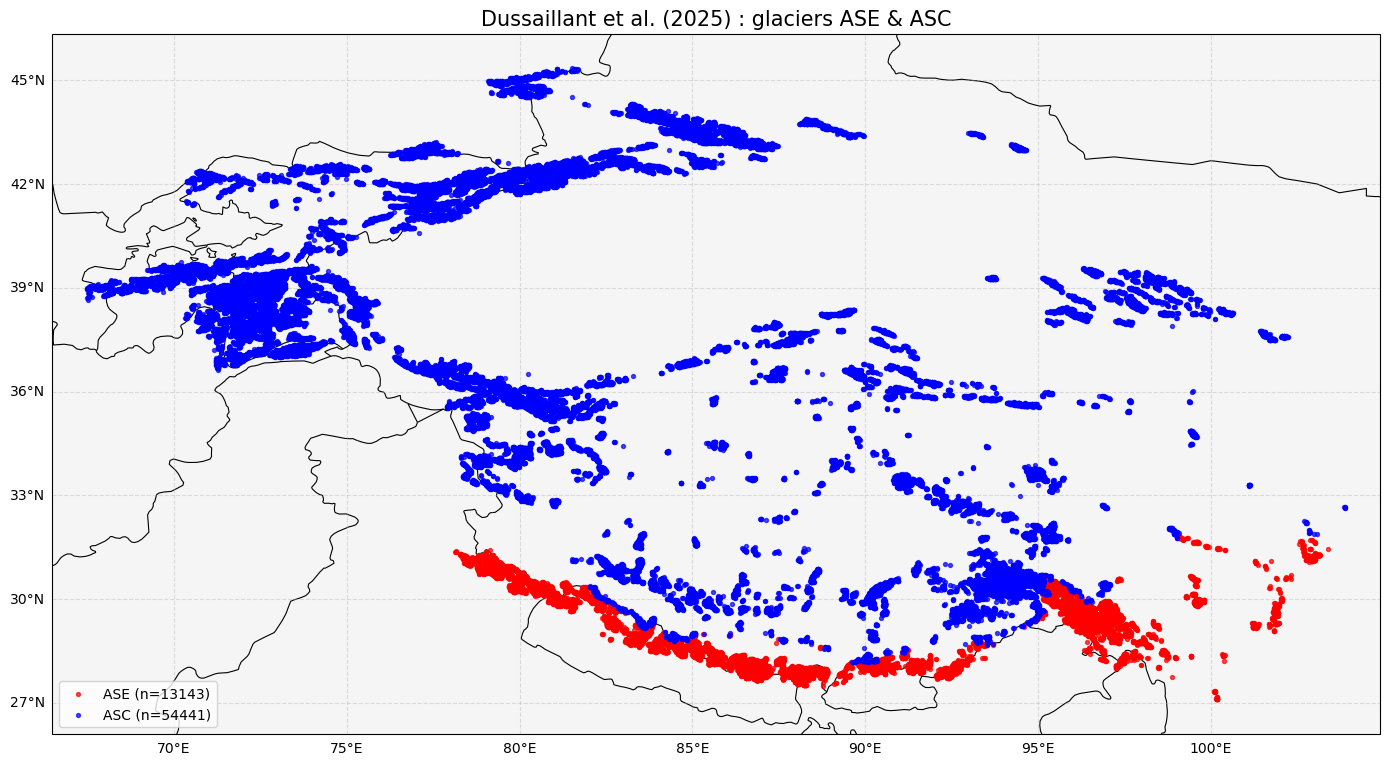

Glaciers ASE  : 13143
Glaciers ASC  : 54441


In [19]:
# 1. Préparer les coordonnées
for df in [dus_ASE_df, dus_ASC_df]:
    df["lat"] = pd.to_numeric(df["lat"], errors="coerce")
    df["lon"] = pd.to_numeric(df["lon"], errors="coerce")

# 2. Supprimer les lignes sans coordonnées valides
glaciers_ASE = dus_ASE_df.dropna(subset=["lat", "lon"]).copy()
glaciers_ASC = dus_ASC_df.dropna(subset=["lat", "lon"]).copy()

# 3. Définir une emprise commune aux deux jeux de données
all_glaciers = pd.concat([
    glaciers_ASE[["lat", "lon"]],
    glaciers_ASC[["lat", "lon"]]
], ignore_index=True)

margin = 1

lon_min = all_glaciers["lon"].min() - margin
lon_max = all_glaciers["lon"].max() + margin
lat_min = all_glaciers["lat"].min() - margin
lat_max = all_glaciers["lat"].max() + margin

# 4. Créer la figure cartographique
fig = plt.figure(figsize=(14, 10))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.set_extent(
    [lon_min, lon_max, lat_min, lat_max],
    crs=ccrs.PlateCarree()
)

# 5. Ajouter le fond géographique
ax.add_feature(cfeature.LAND, facecolor="whitesmoke")
ax.add_feature(cfeature.OCEAN, facecolor="lightblue")
ax.add_feature(cfeature.COASTLINE, linewidth=0.6)

# Frontières des pays
ax.add_feature(
    cfeature.BORDERS,
    edgecolor="black",
    linewidth=0.8,
    linestyle="-"
)

# 6. Glaciers ASE en rouge
ax.scatter(
    glaciers_ASE["lon"],
    glaciers_ASE["lat"],
    s=8,
    color="red",
    alpha=0.7,
    transform=ccrs.PlateCarree(),
    label=f"ASE (n={len(glaciers_ASE)})",
    zorder=5
)

# 7. Glaciers ASC en bleu
ax.scatter(
    glaciers_ASC["lon"],
    glaciers_ASC["lat"],
    s=8,
    color="blue",
    alpha=0.7,
    transform=ccrs.PlateCarree(),
    label=f"ASC (n={len(glaciers_ASC)})",
    zorder=6
)

# 8. Ajouter la grille géographique
gl = ax.gridlines(
    draw_labels=True,
    linestyle="--",
    alpha=0.4
)
gl.top_labels = False
gl.right_labels = False

# 9. Titre et légende
ax.set_title(
    "Dussaillant et al. (2025) : glaciers ASE & ASC",
    fontsize=15
)

ax.legend(loc="lower left")

plt.tight_layout()
plt.show()

# 10. Afficher les statistiques
print(f"Glaciers ASE  : {len(glaciers_ASE)}")
print(f"Glaciers ASC  : {len(glaciers_ASC)}")

In [20]:
# Keep only Dussaillant data included in MAR domain

lat_min, lat_max = LATS.min().values, LATS.max().values
lon_min, lon_max = LONS.min().values, LONS.max().values

dus_ASC_df = dus_ASC_df[
    (dus_ASC_df['lat'].between(lat_min, lat_max)) &
    (dus_ASC_df['lon'].between(lon_min, lon_max))
]

dus_ASE_df = dus_ASE_df[
    (dus_ASE_df['lat'].between(lat_min, lat_max)) &
    (dus_ASE_df['lon'].between(lon_min, lon_max))
]

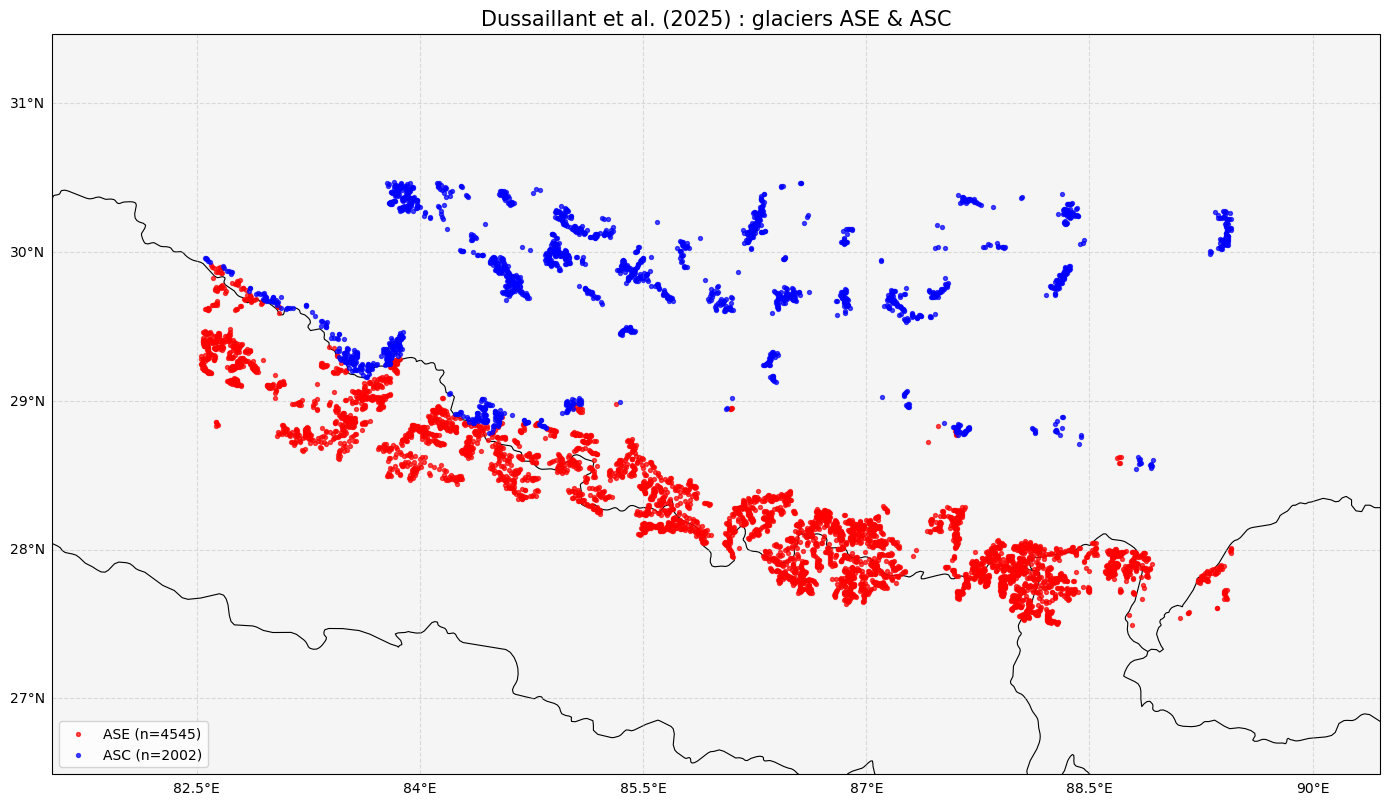

Glaciers ASE  : 4545
Glaciers ASC  : 2002


In [21]:
# 1. Préparer les coordonnées
for df in [dus_ASE_df, dus_ASC_df]:
    df["lat"] = pd.to_numeric(df["lat"], errors="coerce")
    df["lon"] = pd.to_numeric(df["lon"], errors="coerce")

# 2. Supprimer les lignes sans coordonnées valides
glaciers_ASE = dus_ASE_df.dropna(subset=["lat", "lon"]).copy()
glaciers_ASC = dus_ASC_df.dropna(subset=["lat", "lon"]).copy()

# 3. Définir une emprise commune aux deux jeux de données
all_glaciers = pd.concat([
    glaciers_ASE[["lat", "lon"]],
    glaciers_ASC[["lat", "lon"]]
], ignore_index=True)

margin = 1

lon_min = all_glaciers["lon"].min() - margin
lon_max = all_glaciers["lon"].max() + margin
lat_min = all_glaciers["lat"].min() - margin
lat_max = all_glaciers["lat"].max() + margin

# 4. Créer la figure cartographique
fig = plt.figure(figsize=(14, 10))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.set_extent(
    [lon_min, lon_max, lat_min, lat_max],
    crs=ccrs.PlateCarree()
)

# 5. Ajouter le fond géographique
ax.add_feature(cfeature.LAND, facecolor="whitesmoke")
ax.add_feature(cfeature.OCEAN, facecolor="lightblue")
ax.add_feature(cfeature.COASTLINE, linewidth=0.6)

# Frontières des pays
ax.add_feature(
    cfeature.BORDERS,
    edgecolor="black",
    linewidth=0.8,
    linestyle="-"
)

# 6. Glaciers ASE en rouge
ax.scatter(
    glaciers_ASE["lon"],
    glaciers_ASE["lat"],
    s=8,
    color="red",
    alpha=0.7,
    transform=ccrs.PlateCarree(),
    label=f"ASE (n={len(glaciers_ASE)})",
    zorder=5
)

# 7. Glaciers ASC en bleu
ax.scatter(
    glaciers_ASC["lon"],
    glaciers_ASC["lat"],
    s=8,
    color="blue",
    alpha=0.7,
    transform=ccrs.PlateCarree(),
    label=f"ASC (n={len(glaciers_ASC)})",
    zorder=6
)

# 8. Ajouter la grille géographique
gl = ax.gridlines(
    draw_labels=True,
    linestyle="--",
    alpha=0.4
)
gl.top_labels = False
gl.right_labels = False

# 9. Titre et légende
ax.set_title(
    "Dussaillant et al. (2025) : glaciers ASE & ASC",
    fontsize=15
)

ax.legend(loc="lower left")

plt.tight_layout()
plt.show()

# 10. Afficher les statistiques
print(f"Glaciers ASE  : {len(glaciers_ASE)}")
print(f"Glaciers ASC  : {len(glaciers_ASC)}")

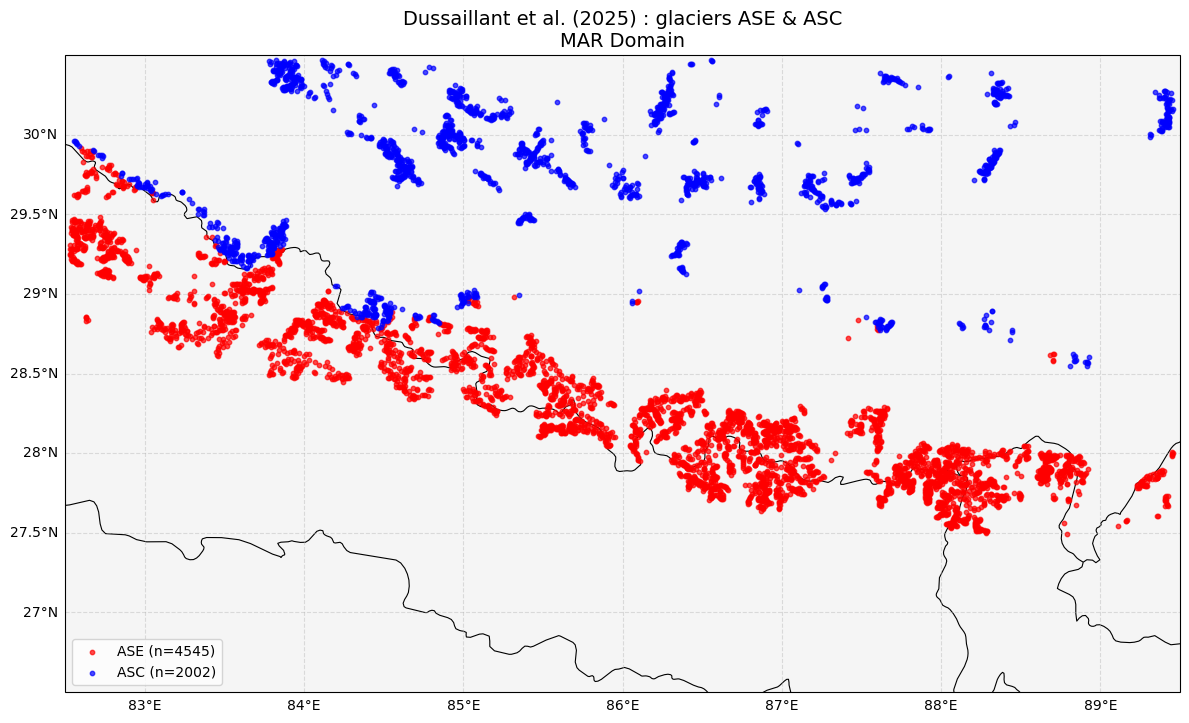

In [22]:
# 1. Préparer les coordonnées
for df in [dus_ASE_df, dus_ASC_df]:
    df["lat"] = pd.to_numeric(df["lat"], errors="coerce")
    df["lon"] = pd.to_numeric(df["lon"], errors="coerce")

# 2. Supprimer les lignes sans coordonnées valides
glaciers_ASE = dus_ASE_df.dropna(subset=["lat", "lon"]).copy()
glaciers_ASC = dus_ASC_df.dropna(subset=["lat", "lon"]).copy()

# 3. Définir la zone géographique
lat_min, lat_max = 26.5, 30.5
lon_min, lon_max = 82.5, 89.5

# Filtrer les glaciers situés dans la zone
glaciers_ASE = glaciers_ASE[
    glaciers_ASE["lat"].between(lat_min, lat_max)
    & glaciers_ASE["lon"].between(lon_min, lon_max)
].copy()

glaciers_ASC = glaciers_ASC[
    glaciers_ASC["lat"].between(lat_min, lat_max)
    & glaciers_ASC["lon"].between(lon_min, lon_max)
].copy()

# 4. Créer la figure cartographique
fig = plt.figure(figsize=(12, 9))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.set_extent(
    [lon_min, lon_max, lat_min, lat_max],
    crs=ccrs.PlateCarree()
)

# 5. Ajouter le fond géographique
ax.add_feature(cfeature.LAND, facecolor="whitesmoke")
ax.add_feature(cfeature.OCEAN, facecolor="lightblue")
ax.add_feature(cfeature.COASTLINE, linewidth=0.6)

# Frontières des pays
ax.add_feature(
    cfeature.BORDERS,
    edgecolor="black",
    linewidth=0.8,
    linestyle="-"
)

# 6. Glaciers ASE en rouge
ax.scatter(
    glaciers_ASE["lon"],
    glaciers_ASE["lat"],
    s=10,
    color="red",
    alpha=0.7,
    transform=ccrs.PlateCarree(),
    label=f"ASE (n={len(glaciers_ASE)})",
    zorder=5
)

# 7. Glaciers ASC en bleu
ax.scatter(
    glaciers_ASC["lon"],
    glaciers_ASC["lat"],
    s=10,
    color="blue",
    alpha=0.7,
    transform=ccrs.PlateCarree(),
    label=f"ASC (n={len(glaciers_ASC)})",
    zorder=6
)

# 8. Grille géographique
gl = ax.gridlines(
    draw_labels=True,
    linestyle="--",
    alpha=0.4
)
gl.top_labels = False
gl.right_labels = False

# 9. Titre et légende
ax.set_title(
    "Dussaillant et al. (2025) : glaciers ASE & ASC\n"
    "MAR Domain",
    fontsize=14
)

ax.legend(loc="lower left")

plt.tight_layout()
plt.show()

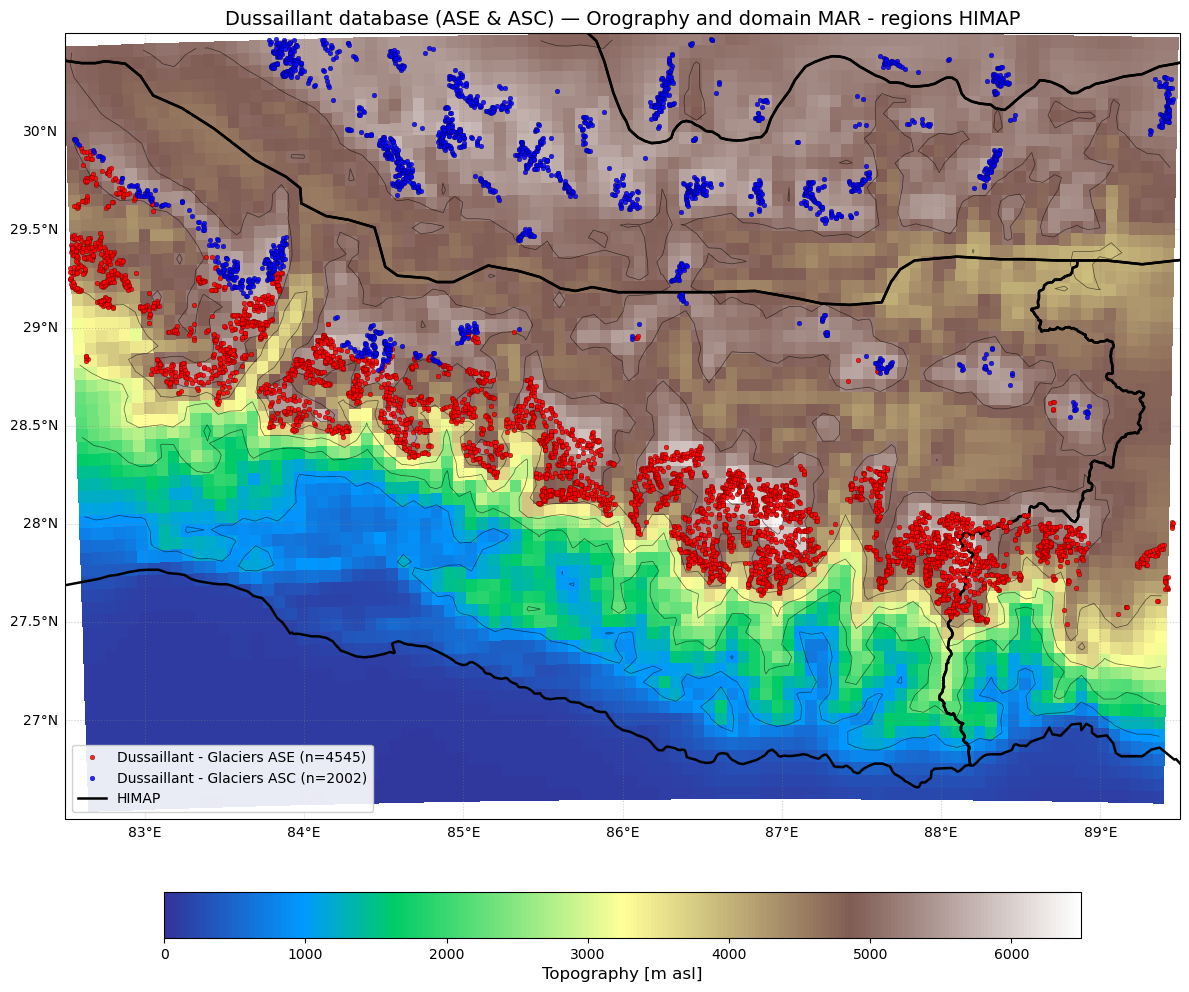

In [23]:
# ============================================================
# 1. PARAMÈTRES GÉOGRAPHIQUES
# ============================================================

lat_min, lat_max = 26.5, 30.5
lon_min, lon_max = 82.5, 89.5

# ============================================================
# 2. PRÉPARATION DES GLACIERS
# ============================================================

for df in [dus_ASE_df, dus_ASC_df]:
    df["lat"] = pd.to_numeric(df["lat"], errors="coerce")
    df["lon"] = pd.to_numeric(df["lon"], errors="coerce")

# Supprimer les lignes sans coordonnées valides
glaciers_ASE = dus_ASE_df.dropna(
    subset=["lat", "lon"]
).copy()

glaciers_ASC = dus_ASC_df.dropna(
    subset=["lat", "lon"]
).copy()

# Filtrer les glaciers dans la zone étudiée
glaciers_ASE = glaciers_ASE[
    glaciers_ASE["lat"].between(lat_min, lat_max)
    & glaciers_ASE["lon"].between(lon_min, lon_max)
].copy()

glaciers_ASC = glaciers_ASC[
    glaciers_ASC["lat"].between(lat_min, lat_max)
    & glaciers_ASC["lon"].between(lon_min, lon_max)
].copy()

# ============================================================
# 3. PRÉPARATION DE LA TOPOGRAPHIE
# ============================================================

# Variables existantes :
# LONS, LATS : coordonnées géographiques
# SH         : altitude en mètres au-dessus du niveau de la mer
# regions    : GeoDataFrame des régions HIMAP

# Si regions n'est pas en coordonnées géographiques, utiliser :
# regions = regions.to_crs("EPSG:4326")

# ============================================================
# 4. CRÉATION DE LA CARTE
# ============================================================

fig = plt.figure(figsize=(12, 10))

ax = fig.add_subplot(
    111,
    projection=ccrs.PlateCarree()
)

ax.set_extent(
    [lon_min, lon_max, lat_min, lat_max],
    crs=ccrs.PlateCarree()
)

# ============================================================
# 5. FOND TOPOGRAPHIQUE
# ============================================================

cmap_mod = plt.get_cmap("terrain")

vmin = 0
vmax = float(SH.max().compute().item())

CS2 = ax.pcolormesh(
    LONS,
    LATS,
    SH,
    cmap=cmap_mod,
    norm=colors.Normalize(vmin=vmin, vmax=vmax),
    transform=ccrs.PlateCarree(),
    shading="auto",
    zorder=1
)

# Courbes de niveau
ax.contour(
    LONS,
    LATS,
    SH,
    levels=[1000, 2000, 3000, 4000, 5000, 6000, 7000],
    colors="black",
    linewidths=0.5,
    alpha=0.6,
    transform=ccrs.PlateCarree(),
    zorder=2
)

# ============================================================
# 6. LIMITES DES RÉGIONS HIMAP
# ============================================================

regions.boundary.plot(
    ax=ax,
    edgecolor="black",
    linewidth=1.8,
    transform=ccrs.PlateCarree(),
    zorder=3
)

# ============================================================
# 7. GLACIERS ASE EN ROUGE
# ============================================================

ax.scatter(
    glaciers_ASE["lon"],
    glaciers_ASE["lat"],
    s=12,
    color="red",
    edgecolors="black",
    linewidths=0.2,
    alpha=0.85,
    transform=ccrs.PlateCarree(),
    label=f"Dussaillant - Glaciers ASE (n={len(glaciers_ASE)})",
    zorder=5
)

# ============================================================
# 8. GLACIERS ASC EN BLEU
# ============================================================

ax.scatter(
    glaciers_ASC["lon"],
    glaciers_ASC["lat"],
    s=12,
    color="blue",
    edgecolors="black",
    linewidths=0.2,
    alpha=0.85,
    transform=ccrs.PlateCarree(),
    label=f"Dussaillant - Glaciers ASC (n={len(glaciers_ASC)})",
    zorder=6
)

# ============================================================
# 9. GRILLE GÉOGRAPHIQUE
# ============================================================

gl = ax.gridlines(
    draw_labels=True,
    linewidth=0.8,
    color="gray",
    alpha=0.4,
    linestyle=":"
)

gl.top_labels = False
gl.right_labels = False

# ============================================================
# 10. BARRE DE COULEUR
# ============================================================

cbar = fig.colorbar(
    CS2,
    ax=ax,
    orientation="horizontal",
    pad=0.08,
    fraction=0.05
)

cbar.set_label(
    "Topography [m asl]",
    fontsize=12
)

# ============================================================
# 11. TITRE ET LÉGENDE
# ============================================================

ax.set_title(
    "Dussaillant database (ASE & ASC) — "
    "Orography and domain MAR - regions HIMAP",
    fontsize=14
)

# Élément de légende pour les frontières HIMAP
himap_legend = Line2D(
    [0], [0],
    color="black",
    linewidth=1.8,
    linestyle="-",
    label="HIMAP"
)

# Récupérer les glaciers et ajouter HIMAP
handles, labels = ax.get_legend_handles_labels()
handles.append(himap_legend)
labels.append("HIMAP")

ax.legend(
    handles=handles,
    labels=labels,
    loc="lower left",
    frameon=True,
    framealpha=0.9
)

plt.tight_layout()
plt.show()

### Création d'un mask pour séparer zones couvertes par ASC et ACE dans Dussaillant et al. (2025)
classification par distance géographique aux glaciers de chaque inventaire :
- ASC : la maille est affectée à l'inventaire ASC si elle est plus proche d'un glacier ASC que du glacier ASE le plus proche.
- ASE : la règle inverse s'applique.
#### Des glaciers des deux domaines ACE et ASC parfois incluent dans la meme cellule MAR
#### Des anomalies ponctuelles dans la classification (eg, glaciers ASE au Tibet)

In [24]:
# ============================================================
# 1. PRÉPARATION DES INVENTAIRES DUSSAILLANT
# ============================================================

glaciers_ASE = dus_ASE_df.copy()
glaciers_ASC = dus_ASC_df.copy()

for df in (glaciers_ASE, glaciers_ASC):
    df["lat"] = pd.to_numeric(df["lat"], errors="coerce")
    df["lon"] = pd.to_numeric(df["lon"], errors="coerce")

    df.dropna(subset=["lat", "lon"], inplace=True)

    df.drop(
        df[
            ~df["lat"].between(-90, 90)
            | ~df["lon"].between(-180, 180)
        ].index,
        inplace=True
    )

if glaciers_ASE.empty or glaciers_ASC.empty:
    raise ValueError("Un inventaire ne contient aucun point valide.")

# ============================================================
# 2. COORDONNÉES DE LA GRILLE MAR
# ============================================================

lons = np.asarray(LONS)
lats = np.asarray(LATS)

if lons.shape != lats.shape:
    raise ValueError("LONS et LATS doivent avoir la même forme.")

# Garder en mémoire les mailles dont les coordonnées sont valides
valid_grid = (
    np.isfinite(lons)
    & np.isfinite(lats)
    & (lats >= -90)
    & (lats <= 90)
    & (lons >= -180)
    & (lons <= 180)
)

# ============================================================
# 3. DISTANCES AUX GLACIERS ASC ET ASE
# ============================================================

coords_ASE = np.deg2rad(
    glaciers_ASE[["lat", "lon"]].to_numpy()
)

coords_ASC = np.deg2rad(
    glaciers_ASC[["lat", "lon"]].to_numpy()
)

tree_ASE = BallTree(coords_ASE, metric="haversine")
tree_ASC = BallTree(coords_ASC, metric="haversine")

# Initialiser les distances à NaN
dist_ASE = np.full(lons.shape, np.nan)
dist_ASC = np.full(lons.shape, np.nan)

# Calculer uniquement pour les mailles valides
grid_coords = np.column_stack([
    lats[valid_grid],
    lons[valid_grid]
])

grid_coords_rad = np.deg2rad(grid_coords)

d_ASE, _ = tree_ASE.query(grid_coords_rad, k=1)
d_ASC, _ = tree_ASC.query(grid_coords_rad, k=1)

earth_radius_km = 6371.0

dist_ASE[valid_grid] = d_ASE[:, 0] * earth_radius_km
dist_ASC[valid_grid] = d_ASC[:, 0] * earth_radius_km

# ============================================================
# 4. CLASSIFICATION EXCLUSIVE
# ============================================================

# 1 = ASE
# 2 = ASC
# NaN = coordonnées de grille invalides uniquement

mask_Dussaillant = np.full(lons.shape, np.nan)

mask_Dussaillant[valid_grid] = np.where(
    dist_ASC[valid_grid] < dist_ASE[valid_grid],
    2,
    1
)

# ============================================================
# 5. RÉSULTATS
# ============================================================

print("Nombre total de mailles :", lons.size)
print("Mailles avec coordonnées valides :", valid_grid.sum())
print("Mailles ASE :", np.sum(mask_Dussaillant == 1))
print("Mailles ASC :", np.sum(mask_Dussaillant == 2))
print(
    "Mailles classées :",
    np.sum(np.isfinite(mask_Dussaillant))
)

assert (
    np.sum(mask_Dussaillant == 1)
    + np.sum(mask_Dussaillant == 2)
    == np.sum(valid_grid)
)

Nombre total de mailles : 5952
Mailles avec coordonnées valides : 5952
Mailles ASE : 3509
Mailles ASC : 2443
Mailles classées : 5952


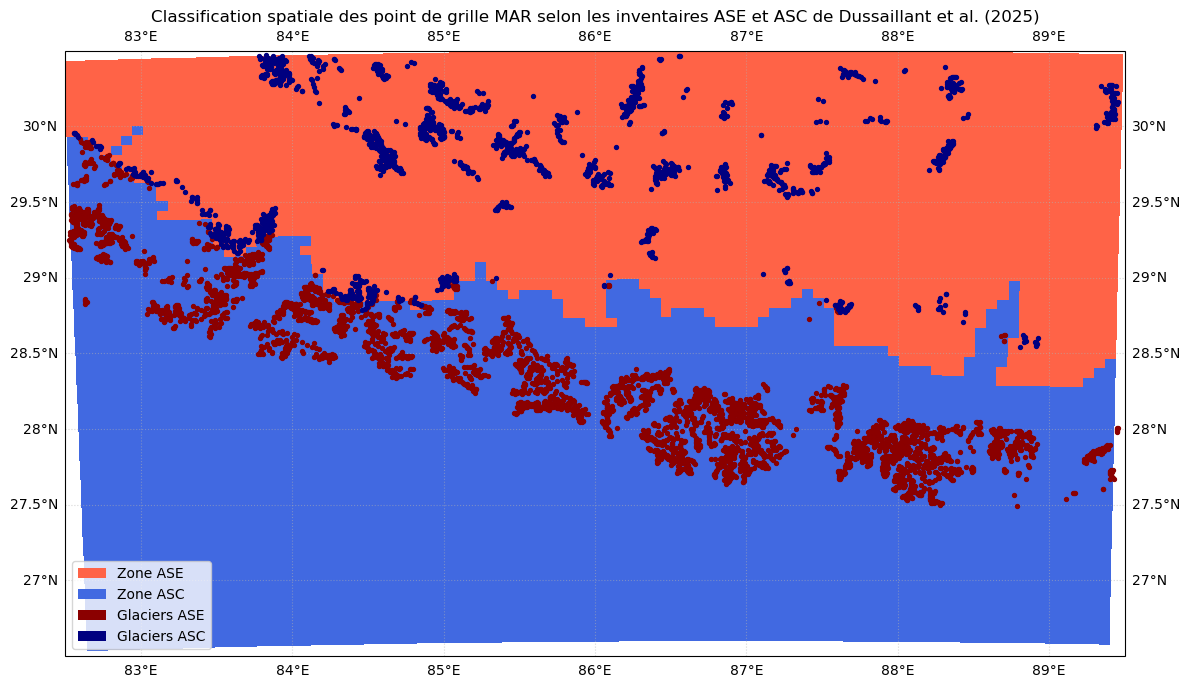

In [25]:
# Des glaciers des deux domaines ACE et ASC parfois incluent dans la meme cellule MAR

fig, ax = plt.subplots(
    figsize=(12, 9),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

ax.set_extent(
    [82.5, 89.5, 26.5, 30.5],
    crs=ccrs.PlateCarree()
)

# Masque des deux groupes
cmap = ListedColormap(["royalblue", "tomato"])

im = ax.pcolormesh(
    LONS,
    LATS,
    mask_Dussaillant,
    cmap=cmap,
    vmin=1,
    vmax=2,
    shading="auto",
    transform=ccrs.PlateCarree(),
    zorder=1
)

# Points des inventaires
ax.scatter(
    glaciers_ASE["lon"],
    glaciers_ASE["lat"],
    s=8,
    color="darkred",
    transform=ccrs.PlateCarree(),
    zorder=3
)

ax.scatter(
    glaciers_ASC["lon"],
    glaciers_ASC["lat"],
    s=8,
    color="navy",
    transform=ccrs.PlateCarree(),
    zorder=3
)

ax.legend(handles=[
    Patch(facecolor="tomato", label="Zone ASE"),
    Patch(facecolor="royalblue", label="Zone ASC"),
    Patch(facecolor="darkred", label="Glaciers ASE"),
    Patch(facecolor="navy", label="Glaciers ASC")
])

ax.coastlines()
ax.gridlines(draw_labels=True, linestyle=":", alpha=0.5)

ax.set_title(
    "Classification spatiale des point de grille MAR selon les inventaires ASE et ASC de Dussaillant et al. (2025)"
)

plt.tight_layout()
plt.show()

In [26]:
# Création d'un mask 
mask_ASE = mask_Dussaillant == 1
mask_ASC = mask_Dussaillant == 2

### Processing Dussaillant data along HIMAP areas 

In [27]:
# Concaténer les deux DataFrames (ajoute les lignes de dus_ASE_df à dus_ASC_df)
dus_df_all = pd.concat([dus_ASC_df, dus_ASE_df], ignore_index=True)

In [29]:
# Extract Dussaillant sub dataset for areas of interest
dus_df_CH = dus_df_all[dus_df_all["OBJECTID"] == 11]
dus_df_EH = dus_df_all[dus_df_all["OBJECTID"] == 12]
dus_df_GM = dus_df_all[dus_df_all["OBJECTID"] == 17]

print('Nombre de glaciers recensés en Central Himalaya:', dus_df_CH.shape[0])
print('Nombre de glaciers recensés en Eastern Himalaya:', dus_df_EH.shape[0])
print('Nombre de glaciers recensés en Gangdise Mountains:', dus_df_GM.shape[0])

Nombre de glaciers recensés en Central Himalaya: 4548
Nombre de glaciers recensés en Eastern Himalaya: 495
Nombre de glaciers recensés en Gangdise Mountains: 1284


In [30]:
dus_df_HIM = pd.concat([dus_df_CH, dus_df_EH], ignore_index=True)

/tmp/ipykernel_1058551/1812800471.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["lat"] = pd.to_numeric(df["lat"], errors="coerce")
/tmp/ipykernel_1058551/1812800471.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["lon"] = pd.to_numeric(df["lon"], errors="coerce")


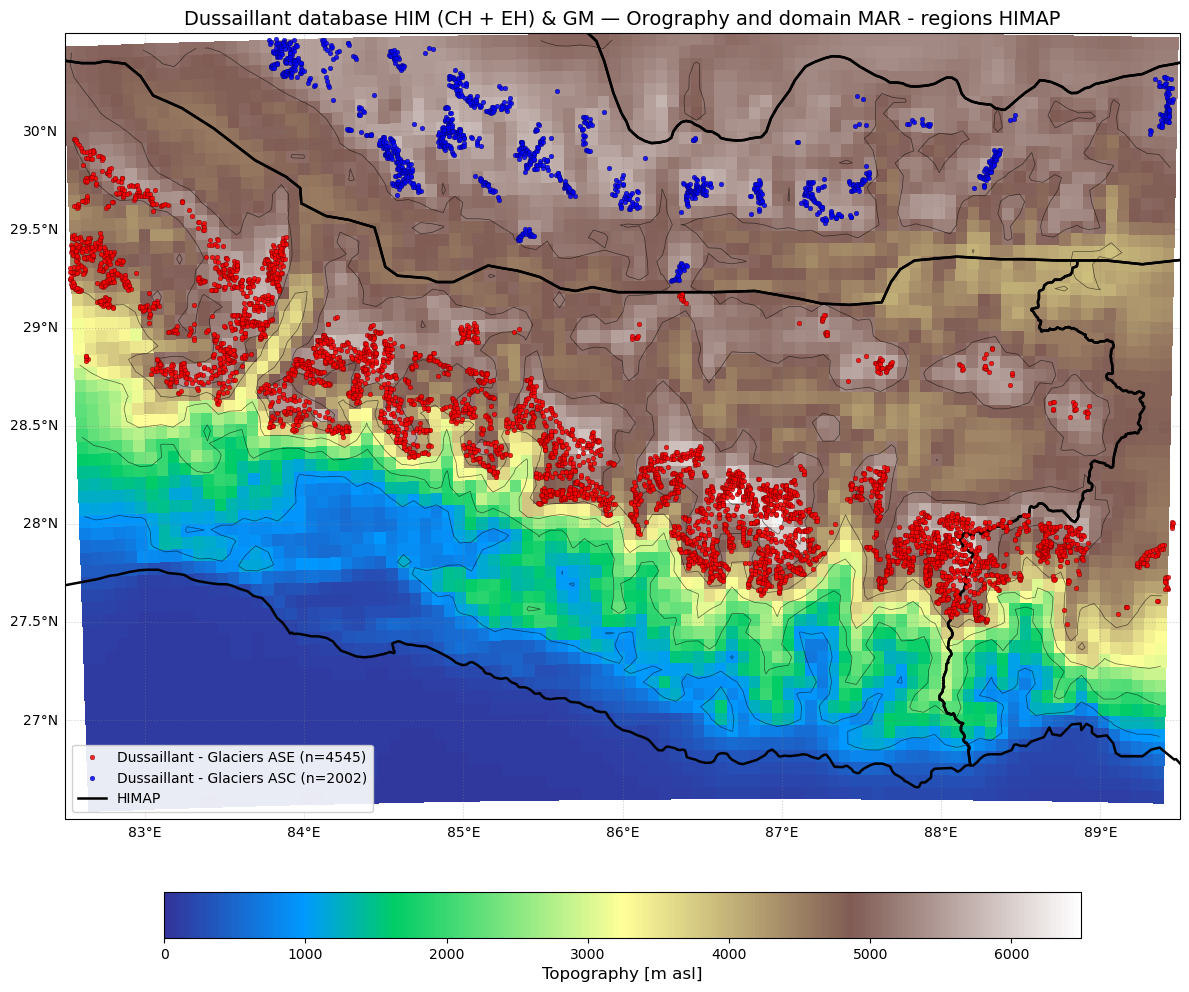

In [31]:
# ============================================================
# 1. PARAMÈTRES GÉOGRAPHIQUES
# ============================================================

lat_min, lat_max = 26.5, 30.5
lon_min, lon_max = 82.5, 89.5

# ============================================================
# 2. PRÉPARATION DES GLACIERS
# ============================================================

for df in [dus_df_HIM, dus_df_GM]:
    df["lat"] = pd.to_numeric(df["lat"], errors="coerce")
    df["lon"] = pd.to_numeric(df["lon"], errors="coerce")

# Supprimer les lignes sans coordonnées valides
glaciers_HIM = dus_df_HIM.dropna(
    subset=["lat", "lon"]
).copy()

glaciers_GM = dus_df_GM.dropna(
    subset=["lat", "lon"]
).copy()

# Filtrer les glaciers dans la zone étudiée
glaciers_HIM = glaciers_HIM[
    glaciers_HIM["lat"].between(lat_min, lat_max)
    & glaciers_HIM["lon"].between(lon_min, lon_max)
].copy()

glaciers_GM = glaciers_GM[
    glaciers_GM["lat"].between(lat_min, lat_max)
    & glaciers_GM["lon"].between(lon_min, lon_max)
].copy()

# ============================================================
# 3. PRÉPARATION DE LA TOPOGRAPHIE
# ============================================================

# Variables existantes :
# LONS, LATS : coordonnées géographiques
# SH         : altitude en mètres au-dessus du niveau de la mer
# regions    : GeoDataFrame des régions HIMAP

# Si regions n'est pas en coordonnées géographiques, utiliser :
# regions = regions.to_crs("EPSG:4326")

# ============================================================
# 4. CRÉATION DE LA CARTE
# ============================================================

fig = plt.figure(figsize=(12, 10))

ax = fig.add_subplot(
    111,
    projection=ccrs.PlateCarree()
)

ax.set_extent(
    [lon_min, lon_max, lat_min, lat_max],
    crs=ccrs.PlateCarree()
)

# ============================================================
# 5. FOND TOPOGRAPHIQUE
# ============================================================

cmap_mod = plt.get_cmap("terrain")

vmin = 0
vmax = float(SH.max().compute().item())

CS2 = ax.pcolormesh(
    LONS,
    LATS,
    SH,
    cmap=cmap_mod,
    norm=colors.Normalize(vmin=vmin, vmax=vmax),
    transform=ccrs.PlateCarree(),
    shading="auto",
    zorder=1
)

# Courbes de niveau
ax.contour(
    LONS,
    LATS,
    SH,
    levels=[1000, 2000, 3000, 4000, 5000, 6000, 7000],
    colors="black",
    linewidths=0.5,
    alpha=0.6,
    transform=ccrs.PlateCarree(),
    zorder=2
)

# ============================================================
# 6. LIMITES DES RÉGIONS HIMAP
# ============================================================

regions.boundary.plot(
    ax=ax,
    edgecolor="black",
    linewidth=1.8,
    transform=ccrs.PlateCarree(),
    zorder=3
)

# ============================================================
# 7. GLACIERS HIM EN ROUGE
# ============================================================

ax.scatter(
    glaciers_HIM["lon"],
    glaciers_HIM["lat"],
    s=12,
    color="red",
    edgecolors="black",
    linewidths=0.2,
    alpha=0.85,
    transform=ccrs.PlateCarree(),
    label=f"Dussaillant - Glaciers ASE (n={len(glaciers_ASE)})",
    zorder=5
)

# ============================================================
# 8. GLACIERS GM EN BLEU
# ============================================================

ax.scatter(
    glaciers_GM["lon"],
    glaciers_GM["lat"],
    s=12,
    color="blue",
    edgecolors="black",
    linewidths=0.2,
    alpha=0.85,
    transform=ccrs.PlateCarree(),
    label=f"Dussaillant - Glaciers ASC (n={len(glaciers_ASC)})",
    zorder=6
)

# ============================================================
# 9. GRILLE GÉOGRAPHIQUE
# ============================================================

gl = ax.gridlines(
    draw_labels=True,
    linewidth=0.8,
    color="gray",
    alpha=0.4,
    linestyle=":"
)

gl.top_labels = False
gl.right_labels = False

# ============================================================
# 10. BARRE DE COULEUR
# ============================================================

cbar = fig.colorbar(
    CS2,
    ax=ax,
    orientation="horizontal",
    pad=0.08,
    fraction=0.05
)

cbar.set_label(
    "Topography [m asl]",
    fontsize=12
)

# ============================================================
# 11. TITRE ET LÉGENDE
# ============================================================

ax.set_title(
    "Dussaillant database HIM (CH + EH) & GM — "
    "Orography and domain MAR - regions HIMAP",
    fontsize=14
)

# Élément de légende pour les frontières HIMAP
himap_legend = Line2D(
    [0], [0],
    color="black",
    linewidth=1.8,
    linestyle="-",
    label="HIMAP"
)

# Récupérer les glaciers et ajouter HIMAP
handles, labels = ax.get_legend_handles_labels()
handles.append(himap_legend)
labels.append("HIMAP")

ax.legend(
    handles=handles,
    labels=labels,
    loc="lower left",
    frameon=True,
    framealpha=0.9
)

plt.tight_layout()
plt.show()

In [114]:
yr_start = 2000
yr_stop = 2024

elev_bins = np.arange(2000, 7000 + dz, dz)

ASC_dus_elevation = mean_smb_remote_sensing_by_elevation(
    dus_ASC_df, yr_start, yr_stop, elev_bins
)

ASE_dus_elevation = mean_smb_remote_sensing_by_elevation(
    dus_ASE_df, yr_start, yr_stop, elev_bins
)

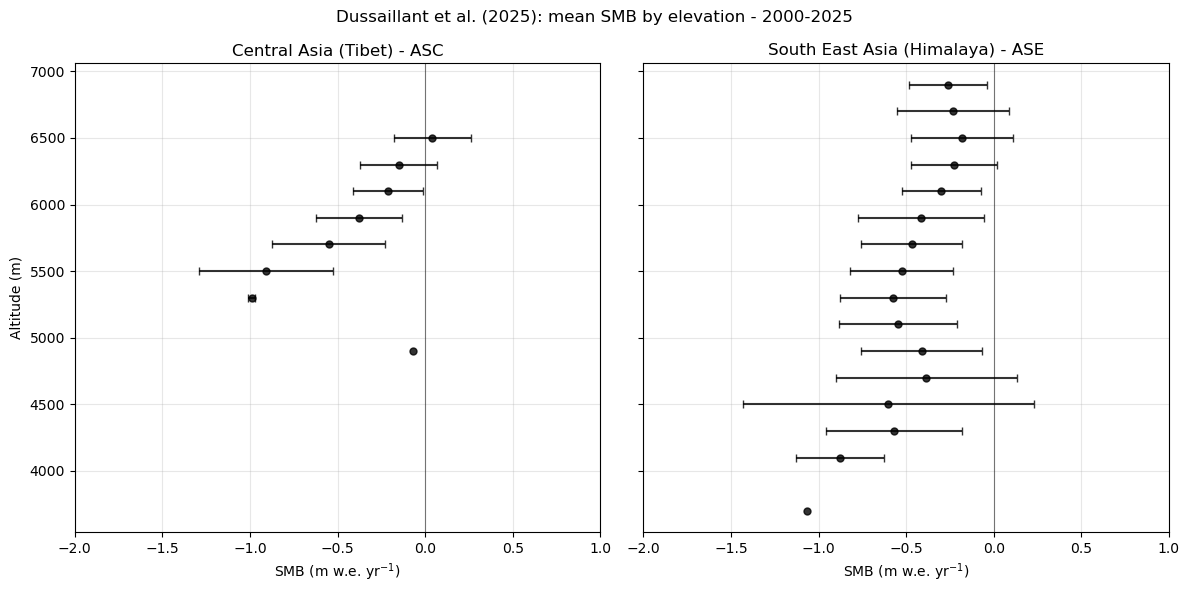

In [115]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 6),
    sharey=True
)

results = [
    ASC_dus_elevation,
    ASE_dus_elevation,
]

titles = [
    "Central Asia (Tibet) - ASC",
    "South East Asia (Himalaya) - ASE",    
]

for ax, result, title in zip(axes, results, titles):
    ax.errorbar(
        result["mean"],
        result["altitude_m"],
        xerr=result["std"],
        fmt="o",
        markersize=5,
        capsize=3,
        alpha=0.8,
        color="black")

    ax.axvline(
        0,
        color="black",
        linewidth=0.8,
        alpha=0.5)

    ax.set_xlim(-2, 1)
    ax.set_title(title)
    ax.set_xlabel("SMB (m w.e. yr$^{-1}$)")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Altitude (m)")

plt.suptitle("Dussaillant et al. (2025): mean SMB by elevation - 2000-2025")

plt.tight_layout()
plt.show()

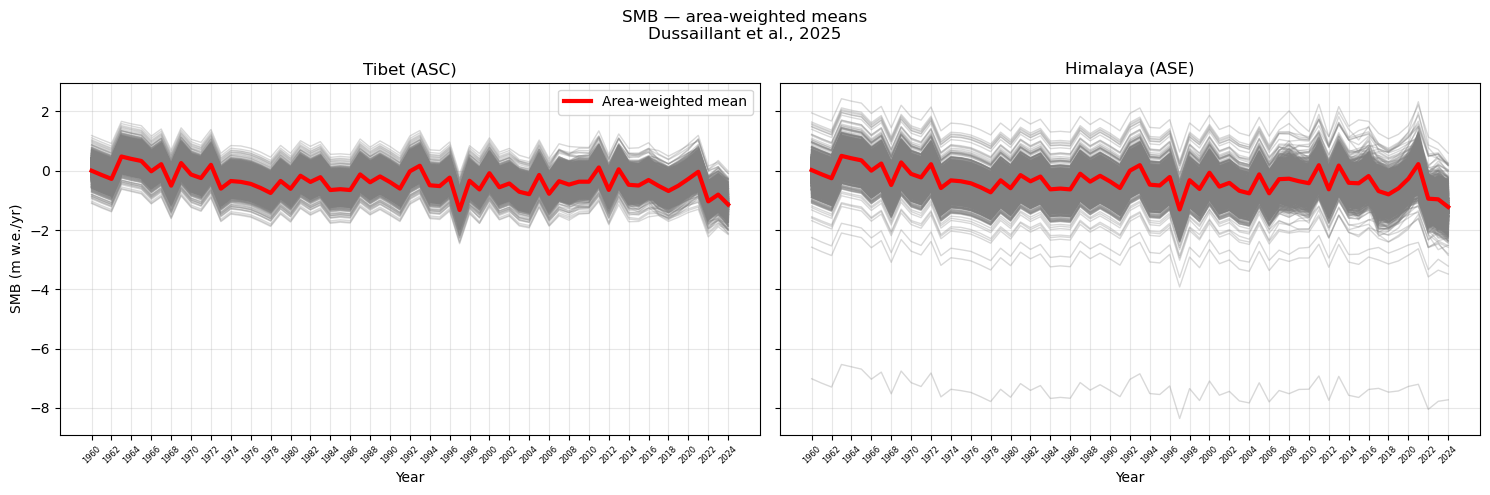

In [34]:
dfs = [dus_ASC_df, dus_ASE_df]
titles = ['Tibet (ASC)', 'Himalaya (ASE)']

yrs = [str(y) for y in range(1960, 2025)]

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5),
    sharex=True,
    sharey=True
)

for ax, df, title in zip(axes, dfs, titles):

    # SMB cumulatif pour chaque glacier
    cum_smb = df[yrs]#.cumsum(axis=1)

    # -----------------------------------------
    # Moyenne pondérée par la surface du glacier
    # -----------------------------------------
    weighted_mean_cum = (
        cum_smb.mul(df["area"], axis=0).sum(axis=0)
        / df["area"].sum()
    )

    # Moyenne pondérée par la surface    
    ax.plot(yrs, cum_smb.T, color='gray', alpha=0.3, lw=1)
    
    ax.plot(
        yrs,
        weighted_mean_cum,
        color='red',
        lw=3,
        label='Area-weighted mean'
    )

    ax.set_title(title)
    ax.set_xlabel('Year')
    ax.tick_params(axis='x', labelsize=6)
    ax.grid(alpha=0.3)


axes[0].set_ylabel('SMB (m w.e./yr)')
axes[0].legend()

plt.suptitle(
    "SMB — area-weighted means\nDussaillant et al., 2025"
)

for ax in axes:
    ax.set_xticks(yrs[::2])
    ax.tick_params(axis='x', labelrotation=45)

plt.tight_layout()
plt.show()

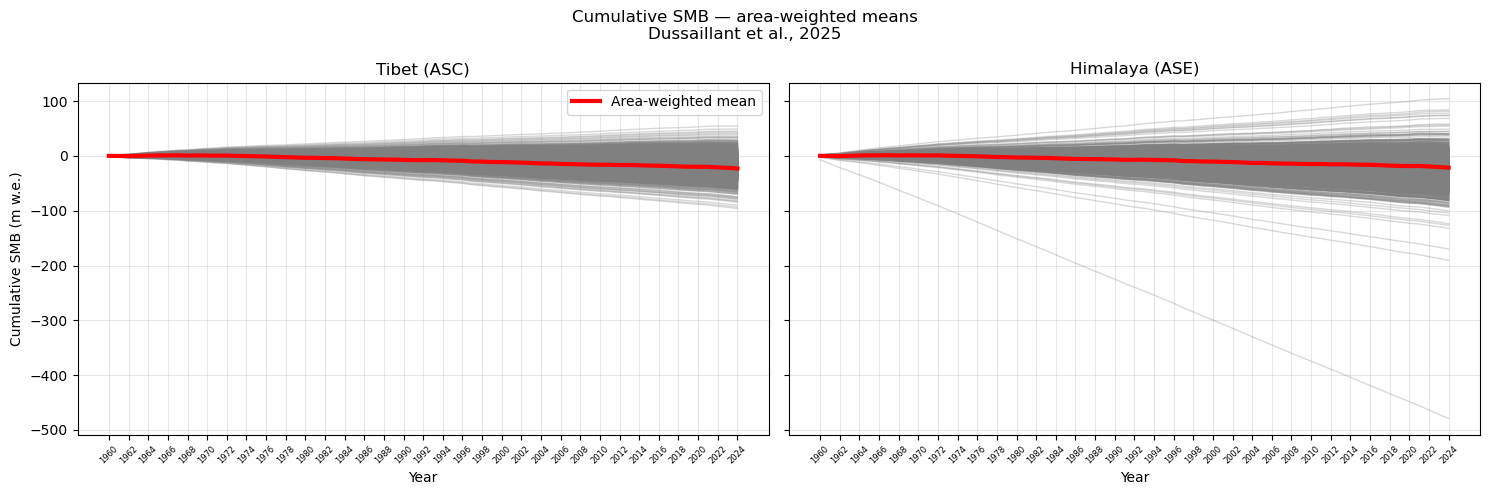

In [35]:
dfs = [dus_ASC_df, dus_ASE_df]
titles = ['Tibet (ASC)', 'Himalaya (ASE)']

yrs = [str(y) for y in range(1960, 2025)]

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5),
    sharex=True,
    sharey=True
)

for ax, df, title in zip(axes, dfs, titles):

    # SMB cumulatif pour chaque glacier
    cum_smb = df[yrs].cumsum(axis=1)

    # -----------------------------------------
    # Moyenne pondérée par la surface du glacier
    # -----------------------------------------
    weighted_mean_cum = (
        cum_smb.mul(df["area"], axis=0).sum(axis=0)
        / df["area"].sum()
    )

    # Moyenne pondérée par la surface    
    ax.plot(yrs, cum_smb.T, color='gray', alpha=0.3, lw=1)
    
    ax.plot(
        yrs,
        weighted_mean_cum,
        color='red',
        lw=3,
        label='Area-weighted mean'
    )

    ax.set_title(title)
    ax.set_xlabel('Year')
    ax.tick_params(axis='x', labelsize=6)
    ax.grid(alpha=0.3)


axes[0].set_ylabel('Cumulative SMB (m w.e.)')
axes[0].legend()

plt.suptitle(
    "Cumulative SMB — area-weighted means\nDussaillant et al., 2025"
)

for ax in axes:
    ax.set_xticks(yrs[::2])
    ax.tick_params(axis='x', labelrotation=45)

plt.tight_layout()
plt.show()

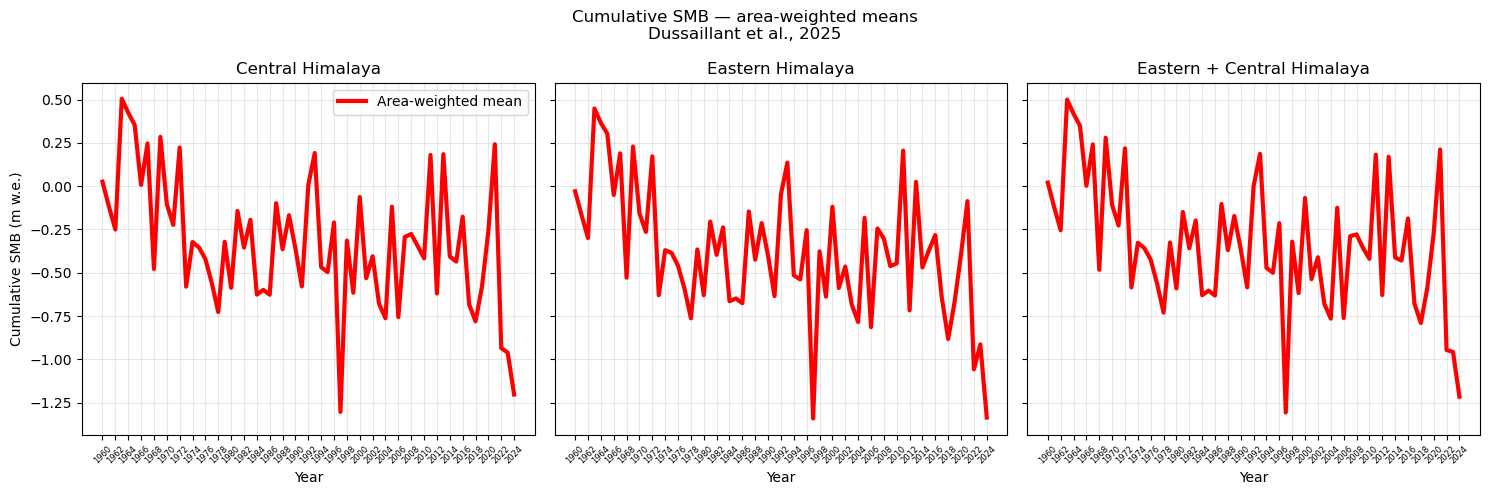

In [103]:
dfs = [dus_df_CH, dus_df_EH, dus_df_HIM]
titles = ['Central Himalaya', 'Eastern Himalaya', 'Eastern + Central Himalaya']

yrs = [str(y) for y in range(1960, 2025)]

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5),
    sharex=True,
    sharey=True
)

for ax, df, title in zip(axes, dfs, titles):

    # SMB cumulatif pour chaque glacier
    cum_smb = df[yrs]#.cumsum(axis=1)

    # -----------------------------------------
    # Moyenne pondérée par la surface du glacier
    # -----------------------------------------
    weighted_mean_cum = (
        cum_smb.mul(df["area"], axis=0).sum(axis=0)
        / df["area"].sum()
    )

    # Moyenne pondérée par la surface    
    
    ax.plot(
        yrs,
        weighted_mean_cum,
        color='red',
        lw=3,
        label='Area-weighted mean'
    )

    ax.set_title(title)
    ax.set_xlabel('Year')
    ax.tick_params(axis='x', labelsize=6)
    ax.grid(alpha=0.3)


axes[0].set_ylabel('Cumulative SMB (m w.e.)')
axes[0].legend()

plt.suptitle(
    "Cumulative SMB — area-weighted means\nDussaillant et al., 2025"
)

for ax in axes:
    ax.set_xticks(yrs[::2])
    ax.tick_params(axis='x', labelrotation=45)

plt.tight_layout()
plt.show()

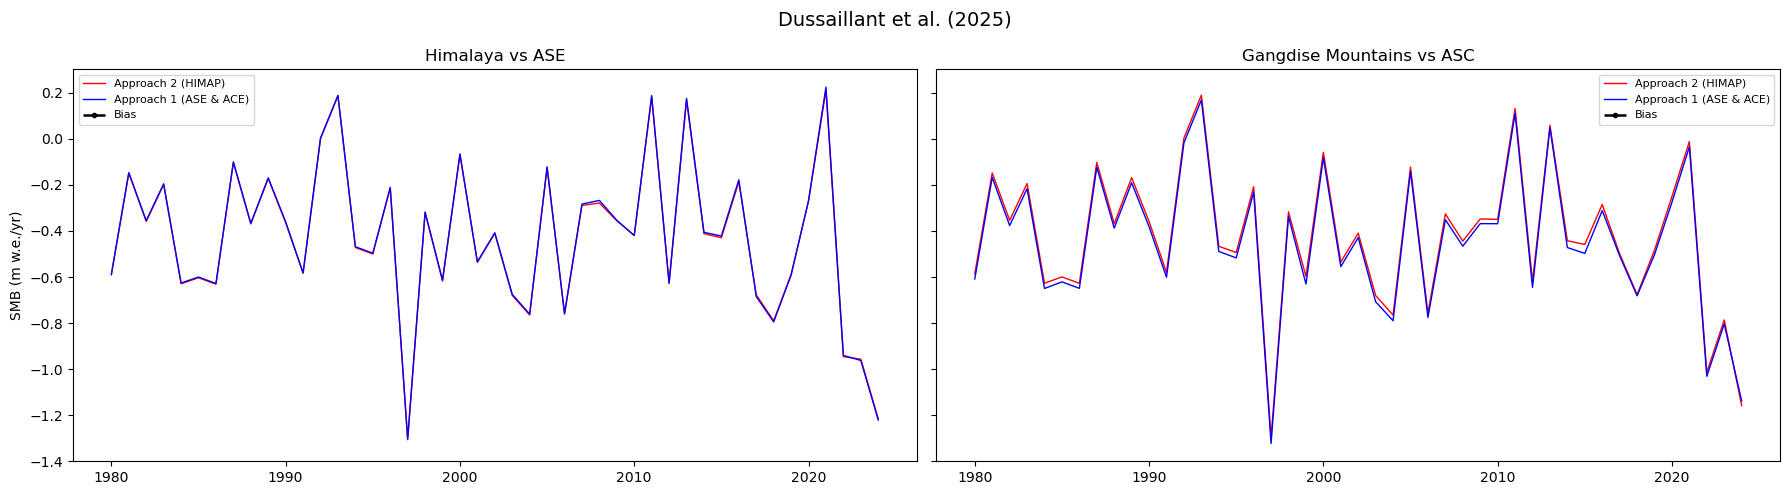

In [113]:
df_1 = [dus_df_HIM, dus_df_GM]
df_2 = [dus_ASE_df, dus_ASC_df]
titles = ['Himalaya vs ASE', 'Gangdise Mountains vs ASC']

yr_start = pd.to_datetime(yr_start_dus).year
yr_stop = pd.to_datetime(yr_stop_dus).year

yrs_str = [str(y) for y in range(yr_start, yr_stop + 1)]

# Limites de l'axe SMB
y1_min = -2
y1_max = 3


# Limites de l'axe du bais
y2_min = -3
y2_max = 2


fig, axes = plt.subplots(
    1, 2,
    figsize=(18, 5),
    sharex=True,
    sharey=True
)

for ax, title, df_1, df_2 in zip(
    axes, titles, df_1, df_2
):

    # ========================================================
    # 1. Dussaillant
    # ========================================================
    cum_smb = df_1[yrs_str]

    weighted_mean_cum = (
        cum_smb.mul(df_1["area"], axis=0).sum(axis=0)
        / df_1["area"].sum()
    )

    years_dus = weighted_mean_cum.index.astype(int).to_numpy()
    values_dus = weighted_mean_cum.to_numpy()

    ax.plot(
        years_dus,
        values_dus,
        lw=1,
        label="Approach 2 (HIMAP)",
        color="red"
    )

    # ========================================================
    # 2. MAR
    # ========================================================
 
    cum_smb_2 = df_2[yrs_str]

    weighted_mean_cum_2 = (
        cum_smb_2.mul(df_2["area"], axis=0).sum(axis=0)
        / df_2["area"].sum()
    )

    years_dus_2 = weighted_mean_cum_2.index.astype(int).to_numpy()
    values_dus_2 = weighted_mean_cum_2.to_numpy()

    ax.plot(
        years_dus_2,
        values_dus_2,
        lw=1,
        label="Approach 1 (ASE & ACE)",
        color="blue"
    )


    # Légende 
    handles1, labels1 = ax.get_legend_handles_labels()
    handles2, labels2 = ax2.get_legend_handles_labels()

    ax.legend(
        handles1 + handles2,
        labels1 + labels2,
        loc="best",
        fontsize=8
    )

    ax.set_title(title)

axes[0].set_ylabel("SMB (m w.e./yr)")

plt.suptitle(
    "Dussaillant et al. (2025)",
    fontsize=14
)

fig.savefig(
    "plots/MAR-DUS_bias_1980_HIM_Approach_2.png",
    dpi=300,
    bbox_inches="tight"
)


plt.tight_layout()
plt.show()

# LOAD MAR DATA

In [36]:
domain = 'GRq'

In [37]:
sourceData_1='/bettik/PROJECTS/pr-regional-climate/santolam/MARout_post/' + domain +'/spin2/work/monthly/'
sourceData_2='/bettik/PROJECTS/pr-regional-climate/fainx/'
sourceData_3='/bettik/PROJECTS/pr-regional-climate/santolam/HARv2/'
folder_figure = '/bettik/PROJECTS/pr-regional-climate/fainx/figures/' + domain +'/'

/tmp/ipykernel_1058551/2803700067.py:42: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


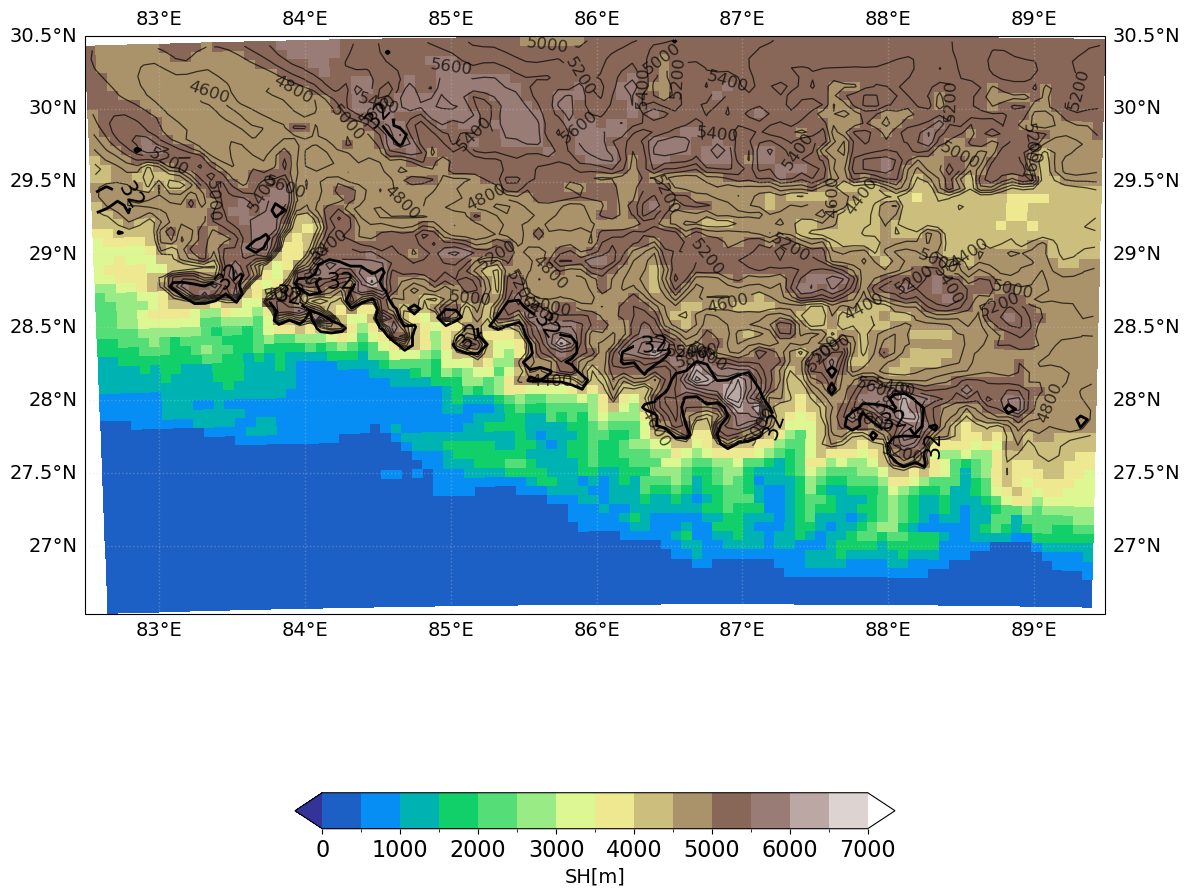

In [38]:
ice_level=32# % of ice on grid cell

clevs=np.arange(0,7500,500)
cmap_mod = plt.get_cmap('terrain')
norm = mcolors.BoundaryNorm(boundaries=clevs, ncolors=cmap_mod.N, extend="both")

fig, ax = plt.subplots(figsize=(12, 12),
                         subplot_kw={'projection': ccrs.PlateCarree()})


im = ax.pcolormesh(LONS, LATS, SH,
                       transform=ccrs.PlateCarree(), cmap=cmap_mod,norm=norm,shading='auto')

ax.set_aspect(1.0)
SH1 = ax.contour(LONS, LATS, SH,
                             levels=[4400,4600,4800,5000,5200,5400,5600,5800,6000,6200,6400,6600,6800,7000],
                             colors="k", linewidths=0.9, alpha=0.7,
                             transform=ccrs.PlateCarree())
ax.clabel(SH1, inline=True, fontsize=12, fmt="%d")
    
ICE2= ax.contour(LONS, LATS, ICE,
                    levels=[ice_level],
                    colors="black", linewidths=2.0, alpha=1.0,
                    transform=ccrs.PlateCarree())

ax.clabel(ICE2, inline=True, fontsize=16, fmt="%d")
 
# ax.set_extent([71, 72, 39.4, 40], crs=ccrs.PlateCarree())

gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                          linewidth=1, color="lightgray", alpha=0.3, linestyle=":")
gl.xlabel_style = {"size": 14}
gl.ylabel_style = {"size": 14}

  
cbar_ax = fig.add_axes([0.25, 0.08, 0.5, 0.03])  # [left, bottom, width, height]
cbar = fig.colorbar(im, cax=cbar_ax, orientation="horizontal")
cbar.set_label(f"{'SH'}[{'m'}]", fontsize=14)
cbar.ax.tick_params(labelsize=16)

fig.subplots_adjust(left=0.2, right=0.8, top=0.95, bottom=0.1, wspace=0.05, hspace=0.2)
plt.tight_layout()

plt.show()

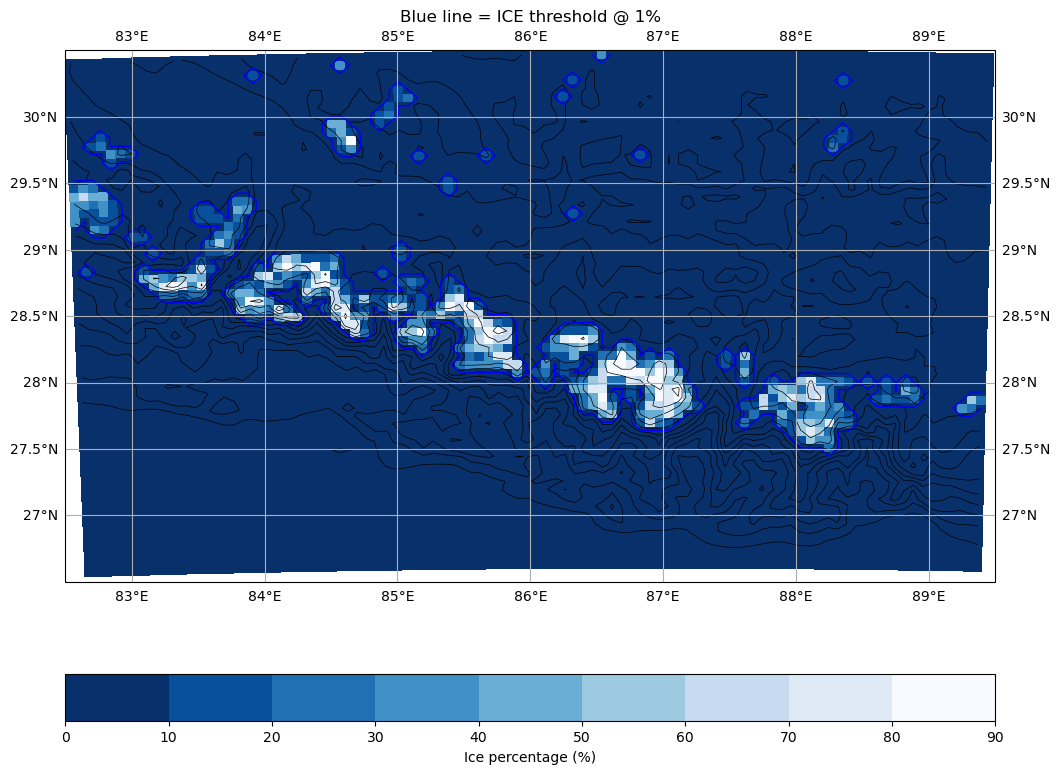

In [76]:
ice_level = 1 # Seuil à partir duquel on considère qu'on observe de la glace

clevs = np.arange(0, 100, 10) # Echelle de couleur de 0 à 100% tous les 10%
cmap = plt.get_cmap("Blues_r") # Palette de couleur bleu (reverse) pour voir le % de glace par grille
norm = mcolors.BoundaryNorm(boundaries=clevs, ncolors=cmap.N) 


fig, ax = plt.subplots(figsize=(12,12),subplot_kw={'projection': ccrs.PlateCarree()}) # Utilisation de la projection plate carré

#### Courbes de niveau (tous les 500m) ####
SH_plot = ax.contour(LONS, LATS, SH, 
           levels=[500,1000,1500,2000,2500,3000,3500,4000,4500,5000,5500,6000,6500,7000], # Affichage des lignes de topographie
           colors="k", linewidths=0.5,
           transform=ccrs.PlateCarree())
#ax.clabel(SH, SH.levels, inline=True, fontsize=6, fmt="%d", inline_spacing=1) # Affiche valeur sur les courbes

#### Countour glaciers ####
ax.contour(LONS, LATS, ICE, 
           levels=[ice_level], # Défini les lignes de contour des glaciers (bleu) où la grille dépasse la valeur de ice_level 
           colors="b", linewidths=1,
           transform=ccrs.PlateCarree())

# #### Mera Peak coord ####
# ax.plot(merap_lon, merap_lat,  # Coord exact du Mera Peak
#         marker='o', markersize=10,
#         markeredgecolor='black', markerfacecolor='red',
#         transform=ccrs.PlateCarree())

#### Percentage of ice ####
im = ax.pcolormesh(LONS, LATS, ICE, 
                   cmap=cmap, norm=norm, # Affiche la couleur du % de glace
                   transform=ccrs.PlateCarree(),
                   shading="auto")
ax.set_extent([82.5, 89.5, 26.5, 30.5], crs=ccrs.PlateCarree()) # Défini les limites (lon, lat) du domaine observable 
#ax.set_extent([86.7, 87.1, 27.6, 27.9], crs=ccrs.PlateCarree()) # Défini les limites (lon, lat) du domaine observable zoom

ax.gridlines(draw_labels=True) # Grille de lattitude et longitude
plt.colorbar(im, orientation="horizontal", pad=0.1, label="Ice percentage (%)") # Paramètres de la barre d'altitude (disposition horizontale / taille / légende)

plt.title(
    "Blue line = ICE threshold @ 1%"
)

plt.show()

In [40]:
variable='SMB' 
#"Surface Mass Balance (SMB~SF+RF-RU-SU-SW)" 

ds_SMB = xr.open_mfdataset(sourceData_1 + "SMB_monsum_MARv3.14_ER5_spin2_GRq_*.nc").SMB.sel(SECTOR=1).load()

ds_SMB = ds_SMB.assign_coords(X=np.round(ds_SMB.X.values))
ds_SMB = ds_SMB.assign_coords(Y=np.round(ds_SMB.Y.values))
ds_SMB = ds_SMB.rename({'TIME': 'time'})

# Enlever k pixels sur les contours
ds_SMB = ds_SMB[:,nx:-nx,nx:-nx]

# Passer en m WE/yr
ds_SMB = ds_SMB/1000

ds_SMB = ds_SMB.chunk({"time": 50, "Y": 62, "X": 96})

In [41]:
# Dans cette analyse je travaille uniquement sur les données SMB des surfaces englaçées
# Ca plot différement sur la carte ci dessous - revoir le sens de SECTOR = 0
ds_SMB_ice = ds_SMB.where(ICE > 0)

In [42]:
mask_smb = xr.DataArray(
    mask,
    dims=("Y", "X"),
    coords={
        "Y": ds_SMB.Y,
        "X": ds_SMB.X
    }
)

In [43]:
# MAR SMB par zone "Dussaillant"
ds_SMB_ASE = ds_SMB_ice.where(mask_ASE)
ds_SMB_ASC = ds_SMB_ice.where(mask_ASC)

In [44]:
ds_SMB_GM = ds_SMB_ice.where(mask_smb == region_id["Gangdise Mountains"])
ds_SMB_CH = ds_SMB_ice.where(mask_smb ==  region_id["Central Himalaya"])
ds_SMB_EH = ds_SMB_ice.where(mask_smb ==  region_id["Eastern Himalaya"])
ds_SMB_TIM = ds_SMB_ice.where(mask_smb ==  region_id["Tibetan Interior Mountains"])

In [45]:
ds_SMB_HIM = ds_SMB_CH.where(~ds_SMB_CH.isnull(), ds_SMB_EH)

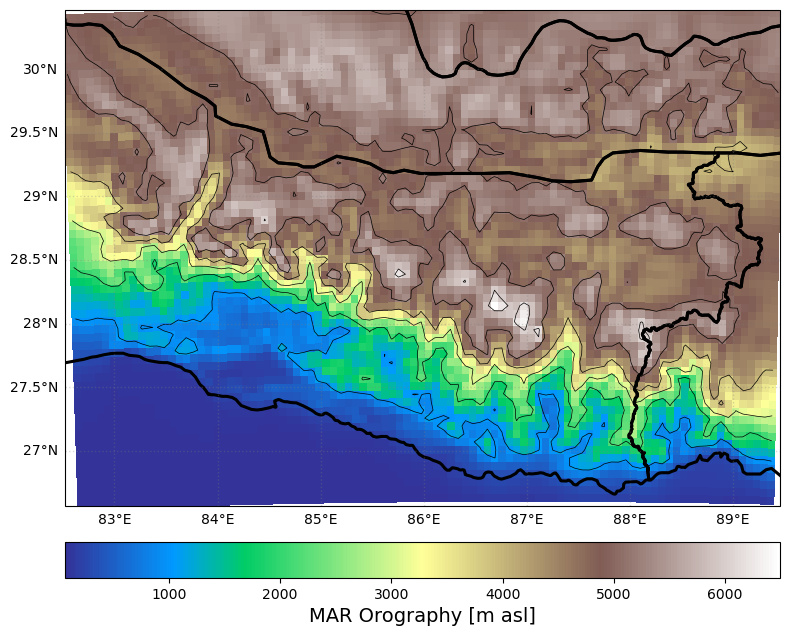

In [46]:
# HIMAP Regions + MAR orography

cmap = 'Red'

norm = colors.Normalize(
    vmin=0,
    vmax = ds_SMB_ASE.isel(time=1).max().compute().item()
)

cmap_mod = plt.get_cmap('terrain')

fig = plt.figure(figsize=(8, 8))
ax2 = fig.add_subplot(111, projection=ccrs.PlateCarree())

ax2.set_extent([
    LONS.min(), LONS.max(),
    LATS.min(), LATS.max()
], crs=ccrs.PlateCarree())


# --- DATA ---
CS2 = ax2.pcolormesh(
    LONS,
    LATS,
    SH,
    cmap=cmap_mod,
    transform=ccrs.PlateCarree(),
    shading="auto"
)

# --- CONTOURS ---
ax2.contour(LONS, LATS, SH,
            levels=[1000, 2000, 3000, 4000, 5000, 6000, 7000],
            colors="k", linewidths=0.5,
            transform=ccrs.PlateCarree())

# --- REGIONS ---
regions.boundary.plot(
    ax=ax2,
    edgecolor='black',
    linewidth=2.2,
    transform=ccrs.PlateCarree()
)

# --- GRIDLINES ---
gl = ax2.gridlines(draw_labels=True,
                   linewidth=1, color="gray",
                   alpha=0.3, linestyle=":")
gl.top_labels = False
gl.right_labels = False

# --- COLORBAR ---
cbar = fig.colorbar(CS2, ax=ax2,
                    orientation="horizontal",
                    pad=0.05, fraction=0.05)

cbar.set_label("MAR Orography [m asl]", fontsize=14)

plt.tight_layout()
plt.show()

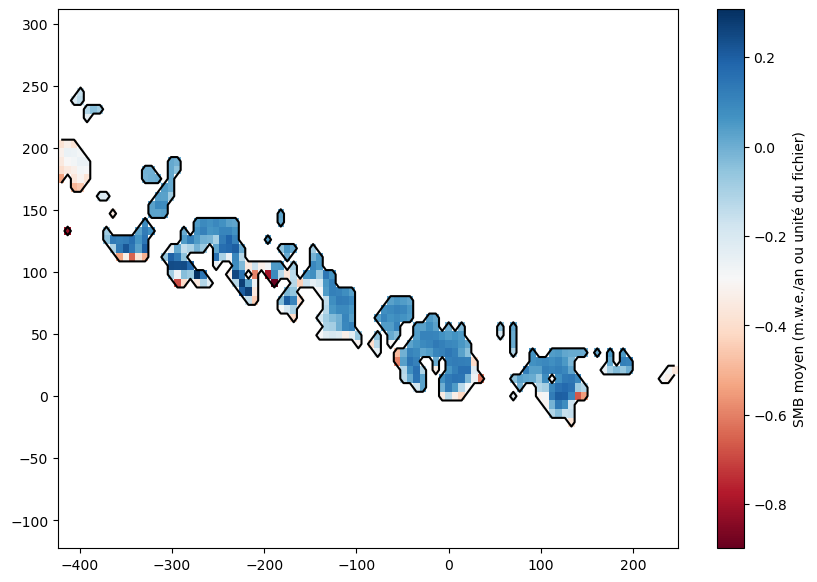

In [47]:
#Verif des cellules considérées

# Masque des points jamais NaN
never_nan = ds_SMB_HIM.notnull().all(dim="time")   # 2D (Y: 62, X: 96)

# Valeur moyenne du SMB en ces points, pour un fond de couleur
smb_mean = ds_SMB_HIM.mean(dim="time")             # DataArray 2D

fig, ax = plt.subplots(figsize=(10, 7))

# Fond : SMB moyen masqué hors zone
smb_bg = np.ma.masked_where(~never_nan.values, smb_mean.values)

# Carte du SMB moyen sur la zone toujours valide
pcm = ax.pcolormesh(smb_mean["X"], smb_mean["Y"], smb_bg,
                    cmap="RdBu", shading="auto")
plt.colorbar(pcm, ax=ax, label="SMB moyen (m.w.e./an ou unité du fichier)")

# Optionnel : contours de la zone jamais NaN
ax.contour(never_nan["X"], never_nan["Y"], never_nan.values.astype(int),
           levels=[0.5], colors="k"
          )

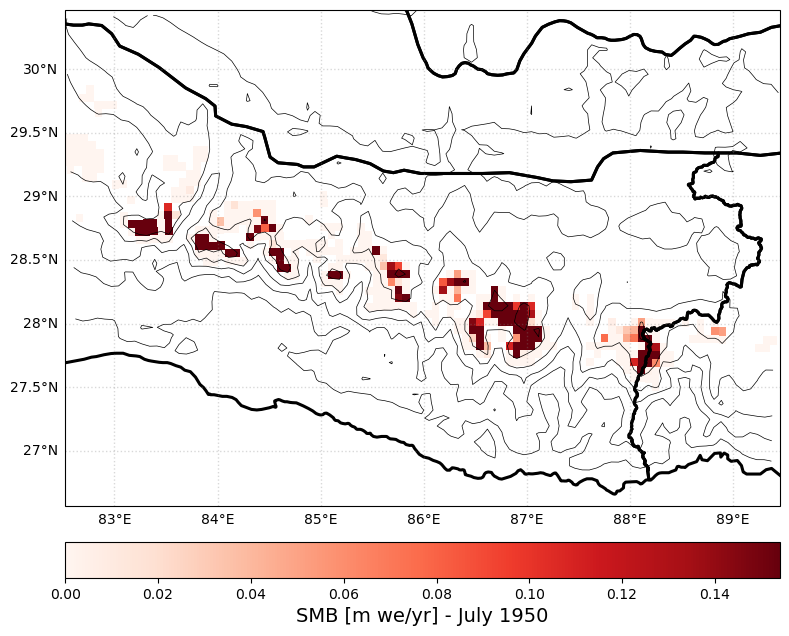

In [48]:
#Verification plot 1 - ZONES HIMAP

cmap = 'Red'

norm = colors.Normalize(
    vmin=0,
    vmax = ds_SMB_HIM.isel(time=1).max().compute().item()
)

fig = plt.figure(figsize=(8, 8))
ax2 = fig.add_subplot(111, projection=ccrs.PlateCarree())

ax2.set_extent([
    LONS.min(), LONS.max(),
    LATS.min(), LATS.max()
], crs=ccrs.PlateCarree())


# --- DATA ---
CS2 = ax2.pcolormesh(
    LONS,
    LATS,
    ds_SMB_HIM.isel(time=6),
    cmap="Reds",
    norm=norm,
    transform=ccrs.PlateCarree(),
    shading="auto"
)

# --- CONTOURS ---
ax2.contour(LONS, LATS, SH,
            levels=[1000, 2000, 3000, 4000, 5000, 6000, 7000],
            colors="k", linewidths=0.5,
            transform=ccrs.PlateCarree())

# --- REGIONS ---
regions.boundary.plot(
    ax=ax2,
    edgecolor='black',
    linewidth=2.2,
    transform=ccrs.PlateCarree()
)

# --- GRIDLINES ---
gl = ax2.gridlines(draw_labels=True,
                   linewidth=1, color="gray",
                   alpha=0.3, linestyle=":")
gl.top_labels = False
gl.right_labels = False

# --- COLORBAR ---
cbar = fig.colorbar(CS2, ax=ax2,
                    orientation="horizontal",
                    pad=0.05, fraction=0.05)

cbar.set_label("SMB [m we/yr] - July 1950", fontsize=14)

plt.tight_layout()
plt.show()

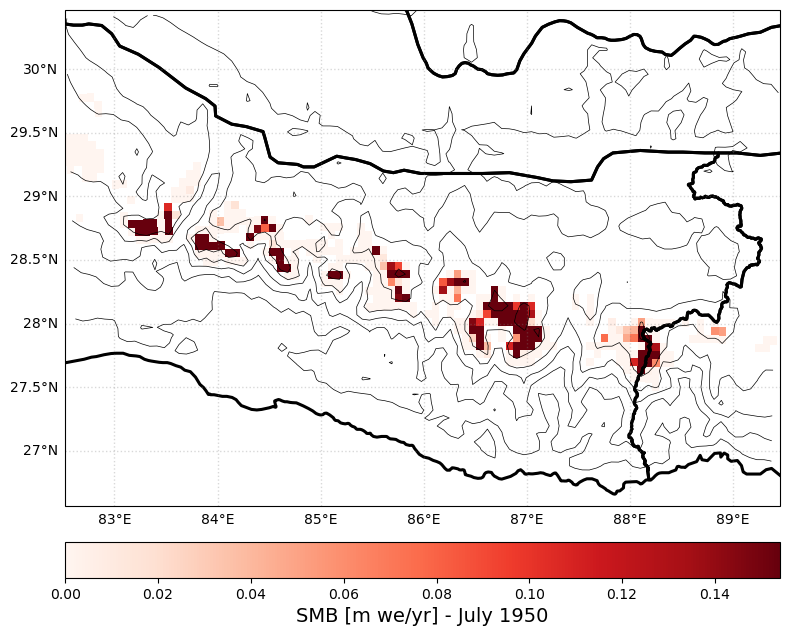

In [49]:
#Verification plot 2 - ZONE DUSSAILLANT

cmap = 'Red'

norm = colors.Normalize(
    vmin=0,
    vmax = ds_SMB_ASE.isel(time=1).max().compute().item()
)

fig = plt.figure(figsize=(8, 8))
ax2 = fig.add_subplot(111, projection=ccrs.PlateCarree())

ax2.set_extent([
    LONS.min(), LONS.max(),
    LATS.min(), LATS.max()
], crs=ccrs.PlateCarree())


# --- DATA ---
CS2 = ax2.pcolormesh(
    LONS,
    LATS,
    ds_SMB_ASE.isel(time=6),
    cmap="Reds",
    norm=norm,
    transform=ccrs.PlateCarree(),
    shading="auto"
)

# --- CONTOURS ---
ax2.contour(LONS, LATS, SH,
            levels=[1000, 2000, 3000, 4000, 5000, 6000, 7000],
            colors="k", linewidths=0.5,
            transform=ccrs.PlateCarree())

# --- REGIONS ---
regions.boundary.plot(
    ax=ax2,
    edgecolor='black',
    linewidth=2.2,
    transform=ccrs.PlateCarree()
)

# --- GRIDLINES ---
gl = ax2.gridlines(draw_labels=True,
                   linewidth=1, color="gray",
                   alpha=0.3, linestyle=":")
gl.top_labels = False
gl.right_labels = False

# --- COLORBAR ---
cbar = fig.colorbar(CS2, ax=ax2,
                    orientation="horizontal",
                    pad=0.05, fraction=0.05)

cbar.set_label("SMB [m we/yr] - July 1950", fontsize=14)

plt.tight_layout()
plt.show()

398 points de grille non-NaN


/home/fainx/micromamba/envs/Xav_2509/lib/python3.9/site-packages/xarray/groupers.py:326: FutureWarning: 'A-SEP' is deprecated and will be removed in a future version, please use 'YE-SEP' instead.
  self.index_grouper = pd.Grouper(
/home/fainx/micromamba/envs/Xav_2509/lib/python3.9/site-packages/xarray/groupers.py:326: FutureWarning: 'A-SEP' is deprecated and will be removed in a future version, please use 'YE-SEP' instead.
  self.index_grouper = pd.Grouper(


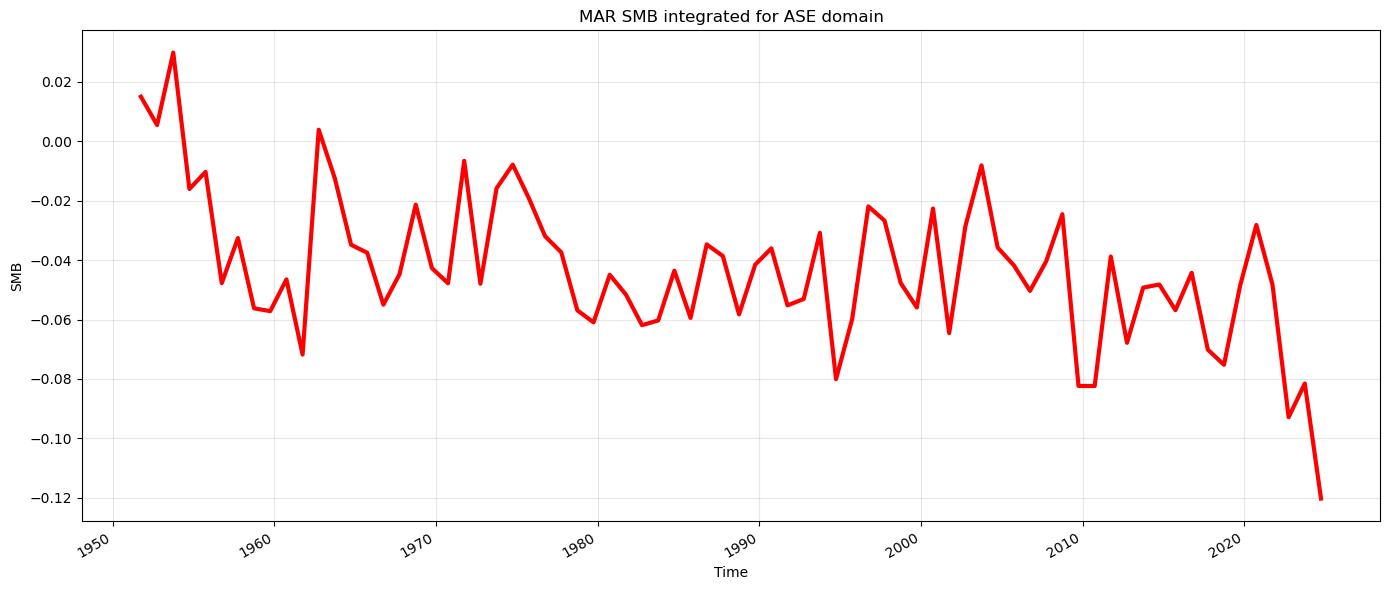

In [50]:
yr_start = '1950-10-01T12:00:00.000000000'
yr_stop  = '2024-09-30T12:00:00.000000000'

df = ds_SMB_ASE.copy()

# Masque : points de grille avec au moins une valeur valide
valid = ~np.isnan(ds_SMB_ASE).all(dim="time")        # DataArray 2D (Y, X)
n_valid = int(valid.sum())
print(f"{n_valid} points de grille non-NaN")


smb_annual = (
    df
    .sel(time=slice(yr_start, yr_stop))
    .resample(time="A-SEP").sum()
)

fig, ax = plt.subplots(figsize=(14, 6))



smb_annual_mean = (
    df
    .sel(time=slice(yr_start, yr_stop))
    .resample(time="A-SEP")
    .sum()
    .mean(dim=["Y", "X"], skipna=True)
)
    
ax.plot(
    smb_annual_mean.time,
    smb_annual_mean,
    color='red',
    lw=3,
    )


ax.set_xlabel("Time")
ax.set_ylabel(ds_SMB_ASE.attrs.get("m we/yr", "SMB"))
ax.set_title(f"MAR SMB integrated for ASE domain")
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

55 points de grille non-NaN


/home/fainx/micromamba/envs/Xav_2509/lib/python3.9/site-packages/xarray/groupers.py:326: FutureWarning: 'A-SEP' is deprecated and will be removed in a future version, please use 'YE-SEP' instead.
  self.index_grouper = pd.Grouper(
/home/fainx/micromamba/envs/Xav_2509/lib/python3.9/site-packages/xarray/groupers.py:326: FutureWarning: 'A-SEP' is deprecated and will be removed in a future version, please use 'YE-SEP' instead.
  self.index_grouper = pd.Grouper(


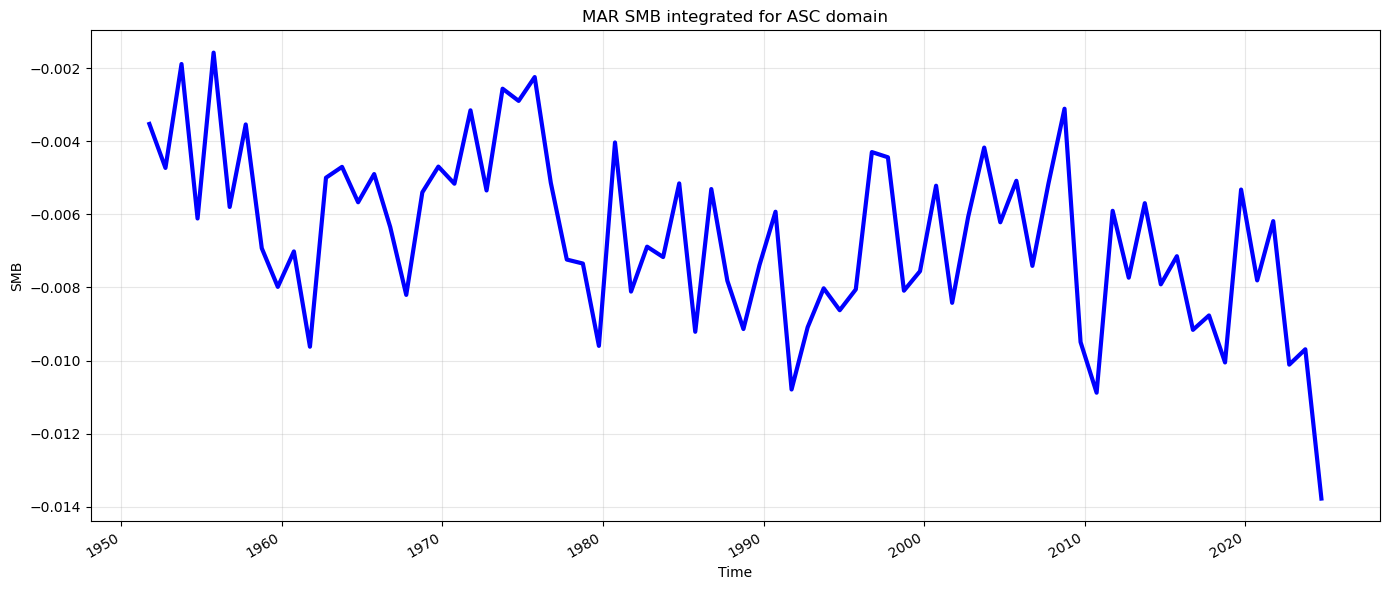

In [51]:
yr_start = '1950-10-01T12:00:00.000000000'
yr_stop  = '2024-09-30T12:00:00.000000000'

df = ds_SMB_ASC.copy()

# Masque : points de grille avec au moins une valeur valide
valid = ~np.isnan(ds_SMB_ASC).all(dim="time")        # DataArray 2D (Y, X)
n_valid = int(valid.sum())
print(f"{n_valid} points de grille non-NaN")


smb_annual = (
    df
    .sel(time=slice(yr_start, yr_stop))
    .resample(time="A-SEP").sum()
)

fig, ax = plt.subplots(figsize=(14, 6))



smb_annual_mean = (
    df
    .sel(time=slice(yr_start, yr_stop))
    .resample(time="A-SEP")
    .sum()
    .mean(dim=["Y", "X"], skipna=True)
)
    
ax.plot(
    smb_annual_mean.time,
    smb_annual_mean,
    color='blue',
    lw=3,
    )


ax.set_xlabel("Time")
ax.set_ylabel(ds_SMB_ASC.attrs.get("m we/yr", "SMB"))
ax.set_title(f"MAR SMB integrated for ASC domain")
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

/home/fainx/micromamba/envs/Xav_2509/lib/python3.9/site-packages/xarray/groupers.py:326: FutureWarning: 'A-SEP' is deprecated and will be removed in a future version, please use 'YE-SEP' instead.
  self.index_grouper = pd.Grouper(
/home/fainx/micromamba/envs/Xav_2509/lib/python3.9/site-packages/xarray/groupers.py:326: FutureWarning: 'A-SEP' is deprecated and will be removed in a future version, please use 'YE-SEP' instead.
  self.index_grouper = pd.Grouper(
/tmp/ipykernel_1058551/3992461186.py:42: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0].legend()


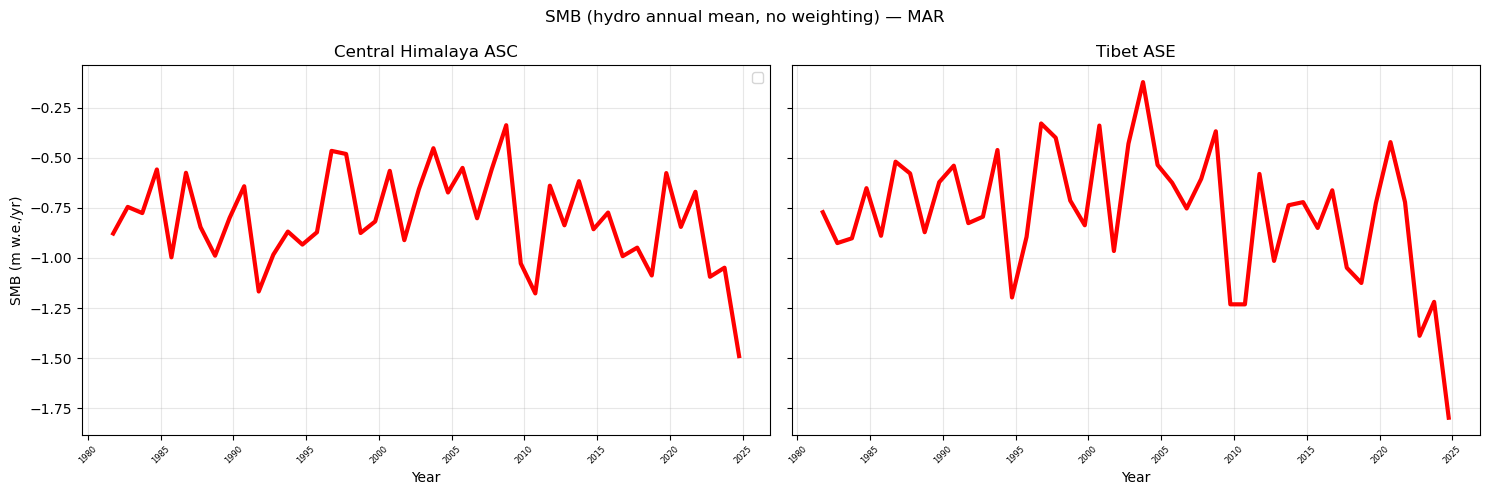

In [52]:
YMIN = -1.5
YMAX =  0.7


dfs = [ds_SMB_ASC, ds_SMB_ASE]
titles = ['Central Himalaya ASC', 'Tibet ASE']

yr_start = '1980-10-01T12:00:00.000000000'
yr_stop  = '2024-09-30T12:00:00.000000000'

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5),
    sharex=True,
    sharey=True
)

for ax, df, title in zip(axes, dfs, titles):
    smb_annual = (
        df
        .sel(time=slice(yr_start, yr_stop))
        .resample(time="A-SEP")
        .sum(min_count=1)
        .mean(dim=["Y", "X"], skipna=True)
    )
    
    ax.plot(
        smb_annual.time,
        smb_annual,
        color='red',
        lw=3,
    )

#    ax.set_ylim(YMIN, YMAX)
    ax.set_title(title)
    ax.set_xlabel('Year')
    ax.tick_params(axis='x', labelsize=6)
    ax.grid(alpha=0.3)


axes[0].set_ylabel('SMB (m w.e./yr)')
axes[0].legend()

plt.suptitle(
    "SMB (hydro annual mean, no weighting) — MAR"
)

for ax in axes:
    ax.tick_params(axis='x', labelrotation=45)

plt.tight_layout()
plt.show()

/home/fainx/micromamba/envs/Xav_2509/lib/python3.9/site-packages/xarray/groupers.py:326: FutureWarning: 'A-SEP' is deprecated and will be removed in a future version, please use 'YE-SEP' instead.
  self.index_grouper = pd.Grouper(
/home/fainx/micromamba/envs/Xav_2509/lib/python3.9/site-packages/xarray/groupers.py:326: FutureWarning: 'A-SEP' is deprecated and will be removed in a future version, please use 'YE-SEP' instead.
  self.index_grouper = pd.Grouper(
/home/fainx/micromamba/envs/Xav_2509/lib/python3.9/site-packages/xarray/groupers.py:326: FutureWarning: 'A-SEP' is deprecated and will be removed in a future version, please use 'YE-SEP' instead.
  self.index_grouper = pd.Grouper(
/tmp/ipykernel_1058551/2184215932.py:42: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0].legend()


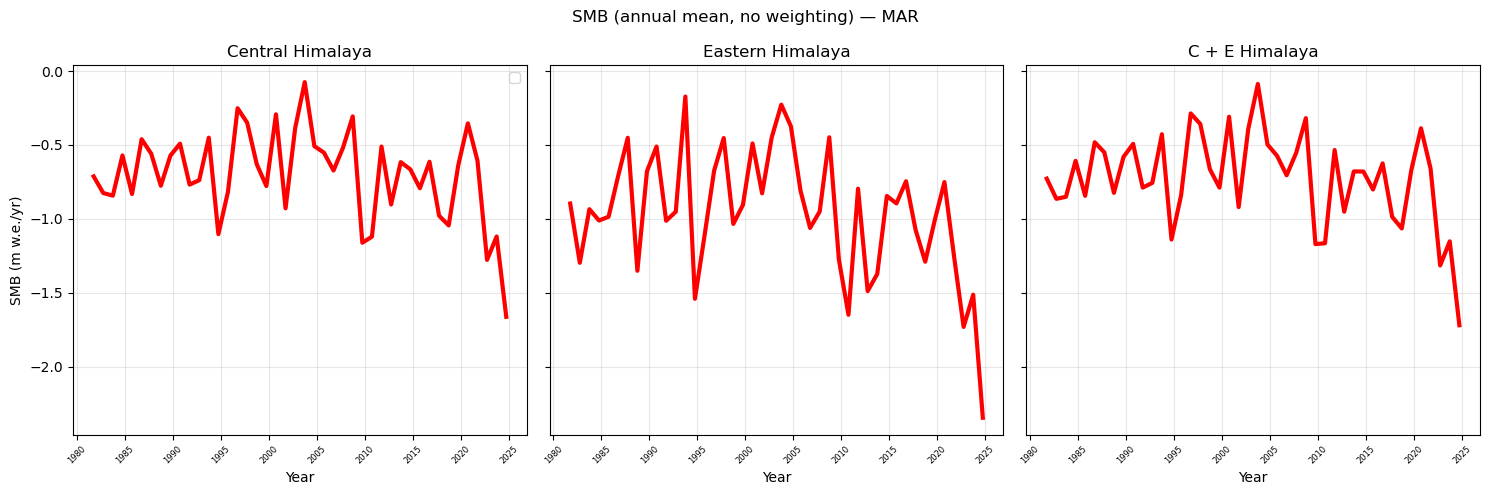

In [95]:
YMIN = -1.5
YMAX =  0.7


dfs = [ds_SMB_CH, ds_SMB_EH, ds_SMB_HIM]
titles = ['Central Himalaya', 'Eastern Himalaya', 'C + E Himalaya']

yr_start = '1980-10-01T12:00:00.000000000'
yr_stop  = '2024-09-30T12:00:00.000000000'

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5),
    sharex=True,
    sharey=True
)

for ax, df, title in zip(axes, dfs, titles):
    smb_annual = (
        df
        .sel(time=slice(yr_start, yr_stop))
        .resample(time="A-SEP")
        .sum(min_count=1)
        .mean(dim=["Y", "X"], skipna=True)
    )
    
    ax.plot(
        smb_annual.time,
        smb_annual,
        color='red',
        lw=3,
    )

#    ax.set_ylim(YMIN, YMAX)
    ax.set_title(title)
    ax.set_xlabel('Year')
    ax.tick_params(axis='x', labelsize=6)
    ax.grid(alpha=0.3)


axes[0].set_ylabel('SMB (m w.e./yr)')
axes[0].legend()

plt.suptitle(
    "SMB (annual mean, no weighting) — MAR"
)

for ax in axes:
    ax.tick_params(axis='x', labelrotation=45)

plt.tight_layout()
plt.show()

In [54]:
elev_bins = np.arange(0, np.nanmax(SH.values.flatten()) + dz, dz)
elev_bin_labels = (elev_bins[:-1] + elev_bins[1:]) / 2

In [55]:
def mean_smb_by_elevation(
    ds_SMB,
    SH,
    yr_start,
    yr_stop,
    elev_bins
):
    # --------------------------------------------------
    # 1. Sélection de la période
    # --------------------------------------------------
    data = ds_SMB.sel(
        time=slice(yr_start, yr_stop)
    )

    # --------------------------------------------------
    # 2. SMB annuel = somme sur chaque année
    # --------------------------------------------------
    data = data.resample(
        time="A-SEP"
    ).sum()

    # --------------------------------------------------
    # 3. Moyenne du SMB annuel sur la période
    # --------------------------------------------------
    data = data.mean(dim="time")

    # --------------------------------------------------
    # 4. Passage en 1D
    # --------------------------------------------------
    elevation = SH.values.flatten()
    smb = data.values.flatten()

    df = pd.DataFrame({
        "elevation": elevation,
        "smb": smb
    })

    # --------------------------------------------------
    # 5. Supprimer les valeurs invalides / nulles
    # --------------------------------------------------
    df = df[
        np.isfinite(df["elevation"]) &
        np.isfinite(df["smb"]) &
        (df["smb"] != 0)
    ]

    # --------------------------------------------------
    # 6. Classes d'altitude
    # --------------------------------------------------
    df["elev_bin"] = pd.cut(
        df["elevation"],
        bins=elev_bins
    )

    # --------------------------------------------------
    # 7. Moyenne + écart-type par altitude
    # --------------------------------------------------
    result = (
        df
        .groupby("elev_bin", observed=True)["smb"]
        .agg(["mean", "std", "count"])
        .reset_index()
    )

    # Centre de chaque classe
    result["altitude_m"] = result["elev_bin"].apply(
        lambda x: x.mid
    )

    return result

### 2020 ou 2024 pour les analyses => demander à Fanny

In [56]:
yr_start = "2000-01-16T12:00:00.000000000"
yr_stop = "2024-12-16T12:00:00.000000000"

result_ASE = mean_smb_by_elevation(
    ds_SMB_ASE,
    SH,
    yr_start,
    yr_stop,
    elev_bins
)

result_ASC = mean_smb_by_elevation(
    ds_SMB_ASC,
    SH,
    yr_start,
    yr_stop,
    elev_bins
)

/home/fainx/micromamba/envs/Xav_2509/lib/python3.9/site-packages/xarray/groupers.py:326: FutureWarning: 'A-SEP' is deprecated and will be removed in a future version, please use 'YE-SEP' instead.
  self.index_grouper = pd.Grouper(
/home/fainx/micromamba/envs/Xav_2509/lib/python3.9/site-packages/xarray/groupers.py:326: FutureWarning: 'A-SEP' is deprecated and will be removed in a future version, please use 'YE-SEP' instead.
  self.index_grouper = pd.Grouper(


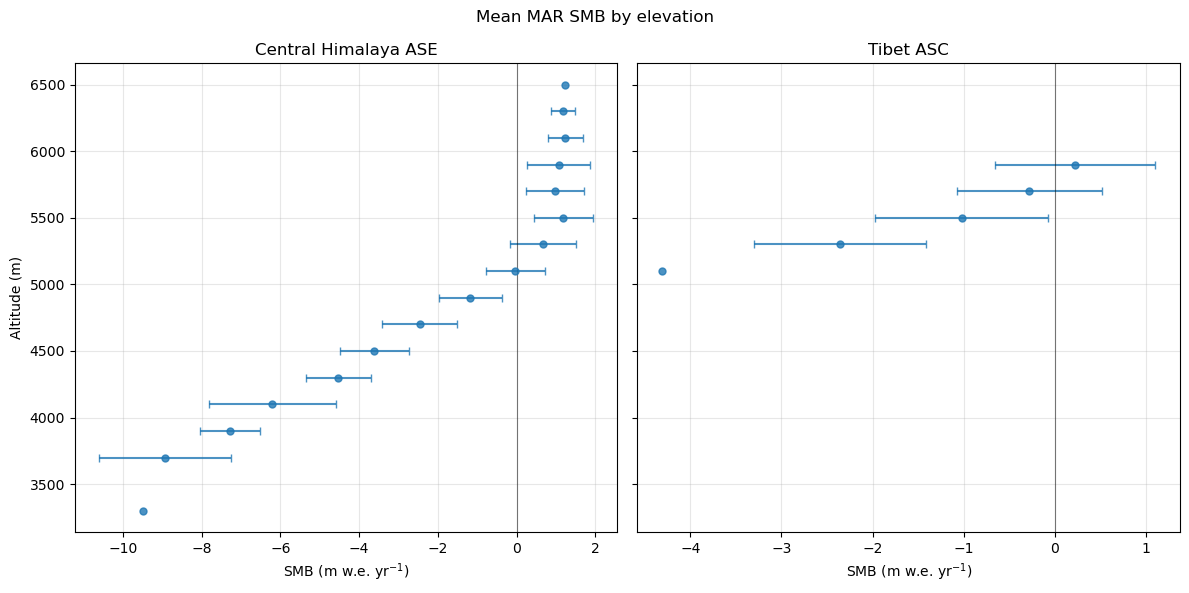

In [57]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 6),
    sharey=True
)

results = [
    result_ASE,
    result_ASC,
]

titles = ['Central Himalaya ASE', 'Tibet ASC']

for ax, result, title in zip(axes, results, titles):

    ax.errorbar(
        result["mean"],
        result["altitude_m"],
        xerr=result["std"],
        fmt="o",
        markersize=5,
        capsize=3,
        alpha=0.8
    )

    ax.axvline(
        0,
        color="black",
        linewidth=0.8,
        alpha=0.5
    )

    ax.set_title(title)
    ax.set_xlabel("SMB (m w.e. yr$^{-1}$)")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Altitude (m)")

plt.suptitle(
    "Mean MAR SMB by elevation"
)

plt.tight_layout()
plt.show()

In [58]:
yr_start = "2000-01-16T12:00:00.000000000"
yr_stop = "2024-12-16T12:00:00.000000000"

result_CH = mean_smb_by_elevation(
    ds_SMB_CH,
    SH,
    yr_start,
    yr_stop,
    elev_bins
)

result_EH = mean_smb_by_elevation(
    ds_SMB_EH,
    SH,
    yr_start,
    yr_stop,
    elev_bins
)

result_GM = mean_smb_by_elevation(
    ds_SMB_GM,
    SH,
    yr_start,
    yr_stop,
    elev_bins
)

/home/fainx/micromamba/envs/Xav_2509/lib/python3.9/site-packages/xarray/groupers.py:326: FutureWarning: 'A-SEP' is deprecated and will be removed in a future version, please use 'YE-SEP' instead.
  self.index_grouper = pd.Grouper(
/home/fainx/micromamba/envs/Xav_2509/lib/python3.9/site-packages/xarray/groupers.py:326: FutureWarning: 'A-SEP' is deprecated and will be removed in a future version, please use 'YE-SEP' instead.
  self.index_grouper = pd.Grouper(
/home/fainx/micromamba/envs/Xav_2509/lib/python3.9/site-packages/xarray/groupers.py:326: FutureWarning: 'A-SEP' is deprecated and will be removed in a future version, please use 'YE-SEP' instead.
  self.index_grouper = pd.Grouper(


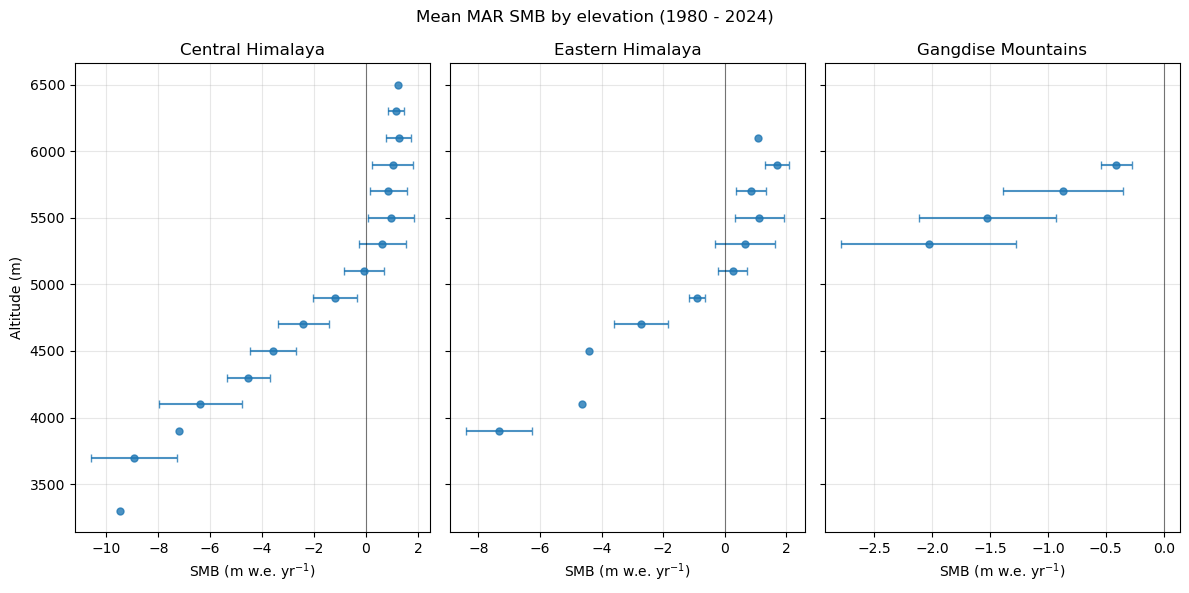

In [59]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(12, 6),
    sharey=True
)

results = [
    result_CH,
    result_EH,
    result_GM
]

titles = ['Central Himalaya', 'Eastern Himalaya', 'Gangdise Mountains']

for ax, result, title in zip(axes, results, titles):

    ax.errorbar(
        result["mean"],
        result["altitude_m"],
        xerr=result["std"],
        fmt="o",
        markersize=5,
        capsize=3,
        alpha=0.8
    )

    ax.axvline(
        0,
        color="black",
        linewidth=0.8,
        alpha=0.5
    )

    ax.set_title(title)
    ax.set_xlabel("SMB (m w.e. yr$^{-1}$)")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Altitude (m)")

plt.suptitle(
    "Mean MAR SMB by elevation (1980 - 2024)"
)

plt.tight_layout()
plt.show()

# COMPARE MAR and Remote Sensing Datasets

## Approach 1 : use ASC and ASE Dussaillant areas

/home/fainx/micromamba/envs/Xav_2509/lib/python3.9/site-packages/xarray/groupers.py:326: FutureWarning: 'A-SEP' is deprecated and will be removed in a future version, please use 'YE-SEP' instead.
  self.index_grouper = pd.Grouper(
/home/fainx/micromamba/envs/Xav_2509/lib/python3.9/site-packages/xarray/groupers.py:326: FutureWarning: 'A-SEP' is deprecated and will be removed in a future version, please use 'YE-SEP' instead.
  self.index_grouper = pd.Grouper(


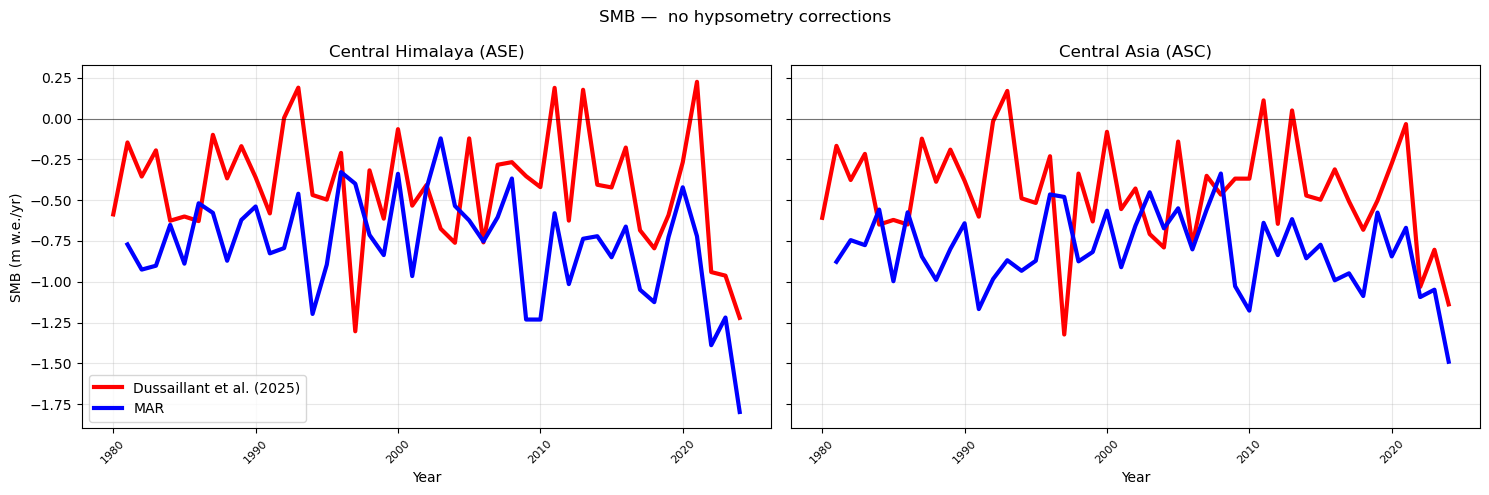

In [60]:
df_remotes_sensing = [dus_ASE_df, dus_ASC_df]
df_mar = [ds_SMB_ASE, ds_SMB_ASC]
titles = ['Central Himalaya (ASE)', 'Central Asia (ASC)']

yr_start_dus = '1980-10-01T12:00:00.000000000'
yr_stop_dus  = '2024-09-30T12:00:00.000000000'

yr_start = pd.to_datetime(yr_start_dus).year
yr_stop = pd.to_datetime(yr_stop_dus).year

# Années pour sélectionner les colonnes de df_dus
yrs_str = [str(y) for y in range(yr_start, yr_stop + 1)]
# Années pour le graphique
yrs = np.arange(yr_start, yr_stop + 1)


fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5),
    sharex=True,
    sharey=True
)

for ax, title, df, smb_mar in zip(
    axes, titles, df_remotes_sensing, df_mar
):

    # ========================================================
    # Remote Sensing dataset
    # ========================================================
    cum_smb = df[yrs_str]#.cumsum(axis=1)
    weighted_mean_cum = (
        cum_smb.mul(df["area"], axis=0).sum(axis=0)
        / df["area"].sum()
    )

    ax.plot(
        yrs,
        weighted_mean_cum,
        lw=3,
        label="Dussaillant et al. (2025)",
        color = 'red'
    )
    # ========================================================
    # MAR
    # ========================================================
    smb_mar_annual = (
        smb_mar
        .sel(time=slice(yr_start_dus, yr_stop_dus))
        .resample(time="A-SEP")
        .sum(min_count=1)
        .mean(dim=["Y", "X"], skipna=True)
    )

    
    ax.plot(
        smb_mar_annual.time.dt.year.values,
        smb_mar_annual,
        lw=3,
        label="MAR",
        color = 'blue'
    )
 
    # ========================================================
    # MISE EN FORME du PLOT
    # ======================================================== 
    ax.set_title(title)
    ax.set_xlabel("Year")
    ax.grid(
        alpha=0.3
    )
    
    ax.axhline(
        0,
        color="black",
        lw=0.8,
        alpha=0.5
    )
    
    ax.tick_params(
        axis="x",
        labelsize=8,
        labelrotation=45
    )

axes[0].set_ylabel(
    "SMB (m w.e./yr)"
)

axes[0].legend()

plt.suptitle(
    "SMB —  no hypsometry corrections"
)

plt.tight_layout()
plt.show()

# Project MAR data on RGI v6 HYPSOMETRIES

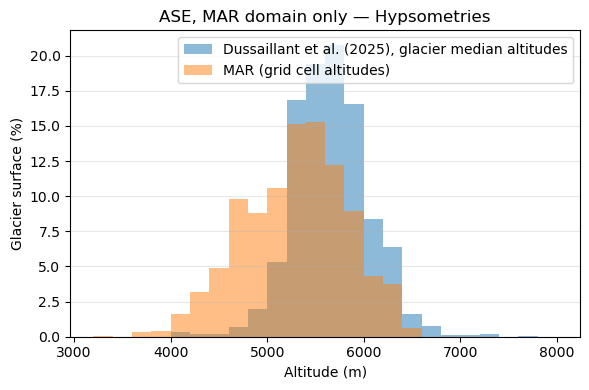

Surface glaciaire totale RGI : 5841.20 km²
Surface glaciaire totale MAR : 7863.15 km²
Somme RGI : 100.00 %
Somme MAR : 100.00 %


In [61]:
# HYPSOMETRIE COMPAREE Dussaillant et MAR - ASE

cell_area = 7 * 7      # km²

# ============================================================
# 1. RGI 6.0 — distribution selon Zmed
# ============================================================

df = dus_ASE_df.copy()

# Surface glaciaire totale RGI
total_area_rgi = df["area"].sum()

# ============================================================
# 2. MAR / ICE — distribution selon altitude
# ============================================================

# Altitudes ASE
altitudes = SH.where(
    (mask_ASE) &
    (ICE > 0)
)


# Surface glaciaire par cellule
ice_area = ICE/100 * cell_area

# Garder uniquement Région + glace
ice_area = ice_area.where(
    (mask_ASE) &
    (ICE > 0)
)

# Conversion en tableaux 1D
altitudes_flat = altitudes.values.flatten()
ice_area_flat = ice_area.values.flatten()

# Retirer les NaN
valid = (
    np.isfinite(altitudes_flat) &
    np.isfinite(ice_area_flat)
)

altitudes_flat = altitudes_flat[valid]
ice_area_flat = ice_area_flat[valid]

# ============================================================
# 3. Classes d'altitude communes aux deux méthodes
# ============================================================

zmin = np.floor(
    min(df["Zmed"].min(), altitudes_flat.min()) / dz
) * dz

zmax = np.ceil(
    max(df["Zmed"].max(), altitudes_flat.max()) / dz
) * dz

bins = np.arange(zmin, zmax + dz, dz)

z_center = (bins[:-1] + bins[1:]) / 2


# ============================================================
# 4. RGI — surface par classe de Zmed
# ============================================================

area_rgi_by_bin, _ = np.histogram(
    df["Zmed"],
    bins=bins,
    weights=df["area"]
)

percentage_rgi = (
    area_rgi_by_bin /
    total_area_rgi
) * 100


# ============================================================
# 5. MAR / ICE — surface par classe d'altitude
# ============================================================

area_mar_by_bin, _ = np.histogram(
    altitudes_flat,
    bins=bins,
    weights=ice_area_flat
)

total_ice_area = area_mar_by_bin.sum()

percentage_mar = (
    area_mar_by_bin /
    total_ice_area
) * 100


# ============================================================
# 6. PLOT COMPARATIF
# ============================================================

plt.figure(figsize=(6, 4))

# RGI 6.0
plt.bar(
    z_center,
    percentage_rgi,
    width=dz,
    align="center",
    alpha=0.5,
    label="Dussaillant et al. (2025), glacier median altitudes"
)

# MAR / ICE
plt.bar(
    z_center,
    percentage_mar,
    width=dz,
    align="center",
    alpha=0.5,
    label="MAR (grid cell altitudes)"
)

plt.xlabel("Altitude (m)")
plt.ylabel("Glacier surface (%)")
plt.title("ASE, MAR domain only — Hypsometries")

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()


# ============================================================
# 7. VÉRIFICATIONS
# ============================================================

print(
    f"Surface glaciaire totale RGI : "
    f"{total_area_rgi:.2f} km²"
)

print(
    f"Surface glaciaire totale MAR : "
    f"{total_ice_area:.2f} km²"
)

print(
    f"Somme RGI : "
    f"{percentage_rgi.sum():.2f} %"
)

print(
    f"Somme MAR : "
    f"{percentage_mar.sum():.2f} %"
)


hypsometry_dus_ASE = pd.DataFrame({
    "altitude_m": z_center,
    "percentage_rgi": percentage_rgi
})

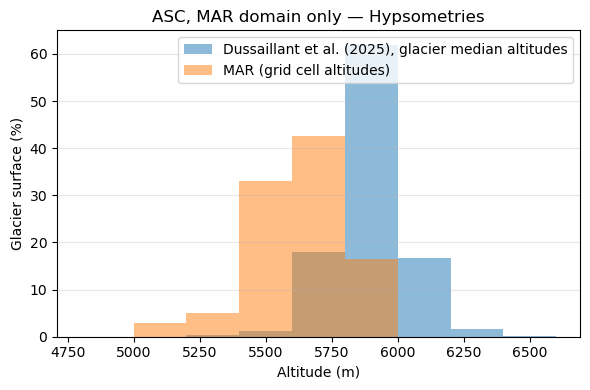

Surface glaciaire totale RGI : 773.63 km²
Surface glaciaire totale MAR : 672.65 km²
Somme RGI : 100.00 %
Somme MAR : 100.00 %


In [62]:
# HYPSOMETRIE COMPAREE Dussaillant et MAR - ASC

cell_area = 7 * 7      # km²

# ============================================================
# 1. RGI 6.0 — distribution selon Zmed
# ============================================================

df = dus_ASC_df.copy()

# Surface glaciaire totale RGI
total_area_rgi = df["area"].sum()

# ============================================================
# 2. MAR / ICE — distribution selon altitude
# ============================================================

# Altitudes ASC
altitudes = SH.where(
    (mask_ASC) &
    (ICE > 0)
)


# Surface glaciaire par cellule
ice_area = ICE/100 * cell_area

# Garder uniquement Région + glace
ice_area = ice_area.where(
    (mask_ASC) &
    (ICE > 0)
)

# Conversion en tableaux 1D
altitudes_flat = altitudes.values.flatten()
ice_area_flat = ice_area.values.flatten()

# Retirer les NaN
valid = (
    np.isfinite(altitudes_flat) &
    np.isfinite(ice_area_flat)
)

altitudes_flat = altitudes_flat[valid]
ice_area_flat = ice_area_flat[valid]

# ============================================================
# 3. Classes d'altitude communes aux deux méthodes
# ============================================================

zmin = np.floor(
    min(df["Zmed"].min(), altitudes_flat.min()) / dz
) * dz

zmax = np.ceil(
    max(df["Zmed"].max(), altitudes_flat.max()) / dz
) * dz

bins = np.arange(zmin, zmax + dz, dz)

z_center = (bins[:-1] + bins[1:]) / 2


# ============================================================
# 4. RGI — surface par classe de Zmed
# ============================================================

area_rgi_by_bin, _ = np.histogram(
    df["Zmed"],
    bins=bins,
    weights=df["area"]
)

percentage_rgi = (
    area_rgi_by_bin /
    total_area_rgi
) * 100


# ============================================================
# 5. MAR / ICE — surface par classe d'altitude
# ============================================================

area_mar_by_bin, _ = np.histogram(
    altitudes_flat,
    bins=bins,
    weights=ice_area_flat
)

total_ice_area = area_mar_by_bin.sum()

percentage_mar = (
    area_mar_by_bin /
    total_ice_area
) * 100


# ============================================================
# 6. PLOT COMPARATIF
# ============================================================

plt.figure(figsize=(6, 4))

# RGI 6.0
plt.bar(
    z_center,
    percentage_rgi,
    width=dz,
    align="center",
    alpha=0.5,
    label="Dussaillant et al. (2025), glacier median altitudes"
)

# MAR / ICE
plt.bar(
    z_center,
    percentage_mar,
    width=dz,
    align="center",
    alpha=0.5,
    label="MAR (grid cell altitudes)"
)

plt.xlabel("Altitude (m)")
plt.ylabel("Glacier surface (%)")
plt.title("ASC, MAR domain only — Hypsometries")

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()


# ============================================================
# 7. VÉRIFICATIONS
# ============================================================

print(
    f"Surface glaciaire totale RGI : "
    f"{total_area_rgi:.2f} km²"
)

print(
    f"Surface glaciaire totale MAR : "
    f"{total_ice_area:.2f} km²"
)

print(
    f"Somme RGI : "
    f"{percentage_rgi.sum():.2f} %"
)

print(
    f"Somme MAR : "
    f"{percentage_mar.sum():.2f} %"
)


hypsometry_dus_ASC = pd.DataFrame({
    "altitude_m": z_center,
    "percentage_rgi": percentage_rgi
})

#### Tres peu de glaciers représentés dans MAR pour la région Tibet => ne pas travailler sur cette région

### l'info SMB MAR donnée à des altitudes non représentées par RGI est "perdue"

### Calcul de MAR projeté sur hypsométrie

In [63]:
def smb_MAR_rgi_projection(ds_SMB, SH, hyps_rgi, yr_start, yr_stop, dz):

    # ============================================================
    # 1. MAR
    # ============================================================

    ds = (
        ds_SMB
        .sel(time=slice(yr_start, yr_stop))
        .resample(time="A-SEP")
        .sum(min_count=1)
    )

    # ============================================================
    # 2. Hypsométrie RGI
    # ============================================================

    altitude_rgi = hyps_rgi["altitude_m"].values
    percentage_rgi = hyps_rgi["percentage_rgi"].values

    # ============================================================
    # 3. Classes d'altitude
    # ============================================================

    bins = np.arange(
        altitude_rgi.min() - dz / 2,
        altitude_rgi.max() + dz / 2 + dz,
        dz
    )

    # ============================================================
    # 4. SMB moyen par classe d'altitude
    # ============================================================

    smb_by_bin = (
        ds
        .groupby_bins(SH, bins=bins)
        .mean(
            dim="stacked_Y_X",
            skipna=True
        )
    )

    # ============================================================
    # 5. SMB moyen pondéré par l'hypsométrie
    # ============================================================

    smb_rgi = (
        smb_by_bin * (percentage_rgi / 100)
    ).sum(
        dim="SH_bins",
        skipna=True
    )

    return smb_rgi

### Projecting MAR SMB on Dussaillant Hypsométries

In [64]:
# Projecting MAR SMB on Dussaillant Hypsométries

yr_start_dus = '1980-01-16T12:00:00.000000000'
yr_stop_dus  = '2024-12-16T12:00:00.000000000'

smb_mar_ASE_dus = smb_MAR_rgi_projection(
    ds_SMB_ASE,
    SH,
    hypsometry_dus_ASE,
    yr_start_dus,
    yr_stop_dus,
    dz
)

smb_mar_ASC_dus = smb_MAR_rgi_projection(
    ds_SMB_ASC,
    SH,
    hypsometry_dus_ASC,
    yr_start_dus,
    yr_stop_dus,
    dz
)

/home/fainx/micromamba/envs/Xav_2509/lib/python3.9/site-packages/xarray/groupers.py:326: FutureWarning: 'A-SEP' is deprecated and will be removed in a future version, please use 'YE-SEP' instead.
  self.index_grouper = pd.Grouper(
/home/fainx/micromamba/envs/Xav_2509/lib/python3.9/site-packages/dask/array/core.py:4849: PerformanceWarning: Increasing number of chunks by factor of 24
  result = blockwise(
/home/fainx/micromamba/envs/Xav_2509/lib/python3.9/site-packages/xarray/groupers.py:326: FutureWarning: 'A-SEP' is deprecated and will be removed in a future version, please use 'YE-SEP' instead.
  self.index_grouper = pd.Grouper(


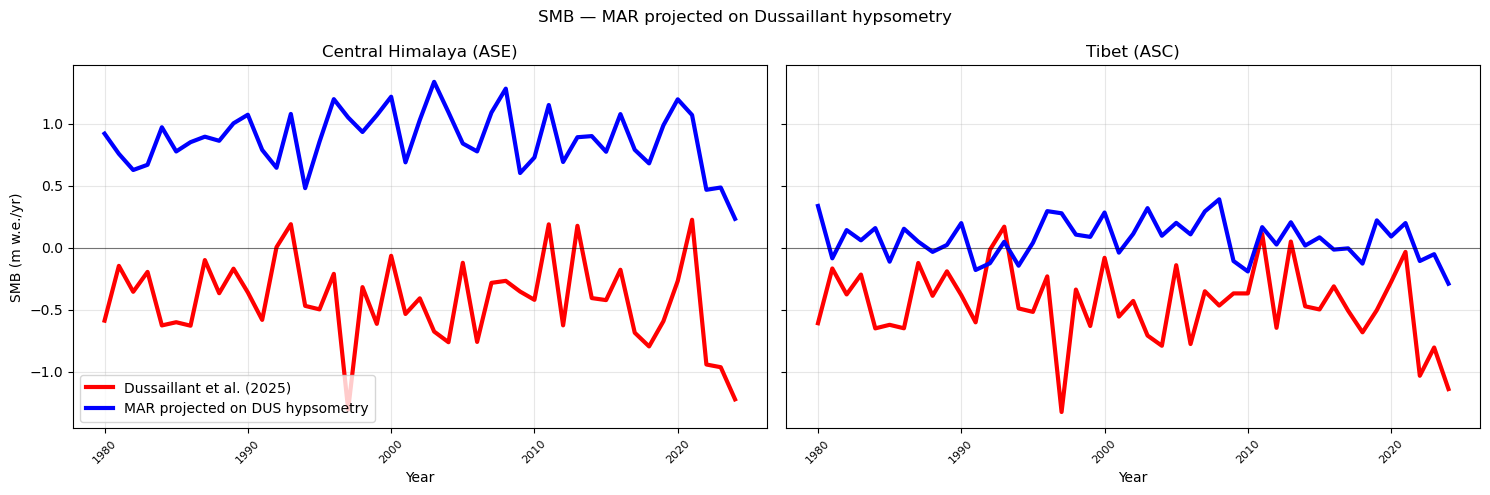

In [65]:
df_remotes_sensing = [dus_ASE_df, dus_ASC_df]
df_mar = [smb_mar_ASE_dus, smb_mar_ASC_dus] # MAR dataset are already projected on DUS hypsometries
titles = ['Central Himalaya (ASE)', 'Tibet (ASC)']

yr_start = pd.to_datetime(yr_start_dus).year
yr_stop = pd.to_datetime(yr_stop_dus).year

# Années pour sélectionner les colonnes de df_dus
yrs_str = [str(y) for y in range(yr_start, yr_stop + 1)]
# Années pour le graphique
yrs = np.arange(yr_start, yr_stop + 1)


fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5),
    sharex=True,
    sharey=True
)


for ax, title, df, smb_mar in zip(
    axes, titles, df_remotes_sensing, df_mar
):

    # ========================================================
    # Remote Sensing dataset
    # ========================================================
    cum_smb = df[yrs_str]#.cumsum(axis=1)
    weighted_mean_cum = (
        cum_smb.mul(df["area"], axis=0).sum(axis=0)
        / df["area"].sum()
    )

    ax.plot(
        yrs,
        weighted_mean_cum,
        lw=3,
        label="Dussaillant et al. (2025)",
        color = 'red'
    )

    # ========================================================
    # MAR
    # ========================================================
    smb_mar_sel = smb_mar.sel(
        time=smb_mar.time.dt.year.isin(
            range(yr_start, yr_stop + 1)
        )
    )
    smb_mar_cum = smb_mar_sel#.cumsum(dim="time")
    
    ax.plot(
        smb_mar_cum.time.dt.year.values,
        smb_mar_cum,
        lw=3,
        label="MAR projected on DUS hypsometry",
        color = 'blue'
    )
    
    # ========================================================
    # MISE EN FORME du PLOT
    # ======================================================== 
    ax.set_title(title)
    ax.set_xlabel("Year")
    ax.grid(
        alpha=0.3
    )
    
    ax.axhline(
        0,
        color="black",
        lw=0.8,
        alpha=0.5
    )
    
    ax.tick_params(
        axis="x",
        labelsize=8,
        labelrotation=45
    )

axes[0].set_ylabel(
    "SMB (m w.e./yr)"
)

axes[0].legend()

plt.suptitle(
    "SMB — MAR projected on Dussaillant hypsometry"
)

fig.savefig(
    "plots/MAR-DUS_1980_HIM.png",
    dpi=300,
    bbox_inches="tight"
)


plt.tight_layout()
plt.show()

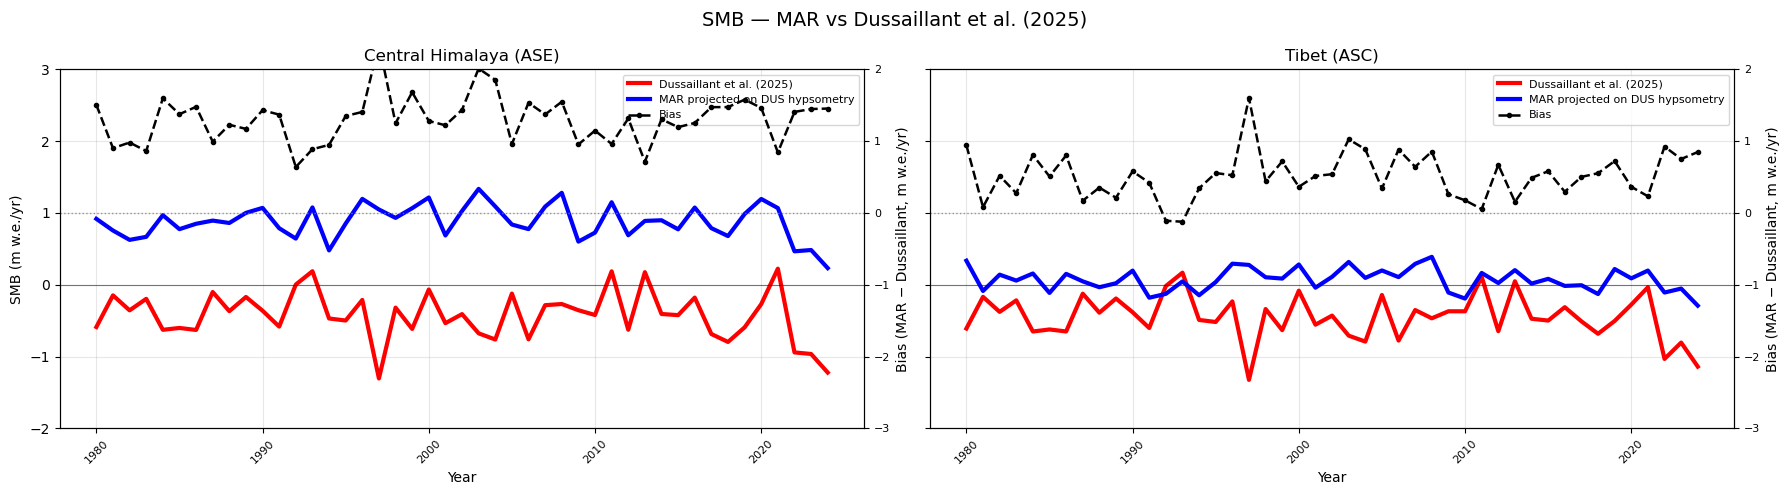

In [66]:
df_remotes_sensing = [dus_ASE_df, dus_ASC_df]
df_mar = [smb_mar_ASE_dus, smb_mar_ASC_dus]
titles = ['Central Himalaya (ASE)', 'Tibet (ASC)']

yr_start = pd.to_datetime(yr_start_dus).year
yr_stop = pd.to_datetime(yr_stop_dus).year

yrs_str = [str(y) for y in range(yr_start, yr_stop + 1)]

# Limites de l'axe SMB
y1_min = -2
y1_max = 3


# Limites de l'axe du bais
y2_min = -3
y2_max = 2


fig, axes = plt.subplots(
    1, 2,
    figsize=(18, 5),
    sharex=True,
    sharey=True
)

for ax, title, df, smb_mar in zip(
    axes, titles, df_remotes_sensing, df_mar
):

    # ========================================================
    # 1. Dussaillant
    # ========================================================
    cum_smb = df[yrs_str]

    weighted_mean_cum = (
        cum_smb.mul(df["area"], axis=0).sum(axis=0)
        / df["area"].sum()
    )

    years_dus = weighted_mean_cum.index.astype(int).to_numpy()
    values_dus = weighted_mean_cum.to_numpy()

    ax.plot(
        years_dus,
        values_dus,
        lw=3,
        label="Dussaillant et al. (2025)",
        color="red"
    )

    # ========================================================
    # 2. MAR
    # ========================================================
    smb_mar_sel = smb_mar.sel(
        time=smb_mar.time.dt.year.isin(
            range(yr_start, yr_stop + 1)
        )
    )

    years_mar = smb_mar_sel.time.dt.year.values
    values_mar = np.asarray(smb_mar_sel.values).squeeze()

    ax.plot(
        years_mar,
        values_mar,
        lw=3,
        label="MAR projected on DUS hypsometry",
        color="blue"
    )
    ax.set_ylim(y1_min, y1_max)
    
    # ========================================================
    # 3. BIAIS MAR - DUSSAILLANT
    # ========================================================
    dus_series = pd.Series(
        values_dus,
        index=years_dus
    )

    mar_series = pd.Series(
        values_mar,
        index=years_mar
    )

    comparison = pd.concat(
        [
            mar_series.rename("MAR"),
            dus_series.rename("DUS")
        ],
        axis=1,
        join="inner"
    ).sort_index()

    difference = comparison["MAR"] - comparison["DUS"]

    ax2 = ax.twinx()

    ax2.plot(
        difference.index,
        difference.values,
        color="black",
        lw=1.8,
        linestyle="--",
        marker="o",
        markersize=3,
        label="Bias"
    )

    ax2.axhline(
        0,
        color="gray",
        lw=1,
        linestyle=":",
        alpha=0.8
    )

    ax2.set_ylim(y2_min, y2_max)
    ax2.set_ylabel(
        "Bias (MAR − Dussaillant, m w.e./yr)",
        color="black"
    )

    ax2.tick_params(
        axis="y",
        labelsize=8,
        colors="black"
    )

    ax.set_title(title)
    ax.set_xlabel("Year")
    ax.grid(alpha=0.3)

    ax.axhline(
        0,
        color="black",
        lw=0.8,
        alpha=0.5
    )

    ax.tick_params(
        axis="x",
        labelsize=8,
        labelrotation=45
    )

    # Légende 
    handles1, labels1 = ax.get_legend_handles_labels()
    handles2, labels2 = ax2.get_legend_handles_labels()

    ax.legend(
        handles1 + handles2,
        labels1 + labels2,
        loc="best",
        fontsize=8
    )

axes[0].set_ylabel("SMB (m w.e./yr)")

plt.suptitle(
    "SMB — MAR vs Dussaillant et al. (2025)",
    fontsize=14
)

fig.savefig(
    "plots/MAR-DUS_bias_1980_HIM.png",
    dpi=300,
    bbox_inches="tight"
)


plt.tight_layout()
plt.show()

/home/fainx/micromamba/envs/Xav_2509/lib/python3.9/site-packages/xarray/groupers.py:326: FutureWarning: 'A-SEP' is deprecated and will be removed in a future version, please use 'YE-SEP' instead.
  self.index_grouper = pd.Grouper(
/home/fainx/micromamba/envs/Xav_2509/lib/python3.9/site-packages/dask/array/core.py:4849: PerformanceWarning: Increasing number of chunks by factor of 24
  result = blockwise(
/home/fainx/micromamba/envs/Xav_2509/lib/python3.9/site-packages/xarray/groupers.py:326: FutureWarning: 'A-SEP' is deprecated and will be removed in a future version, please use 'YE-SEP' instead.
  self.index_grouper = pd.Grouper(


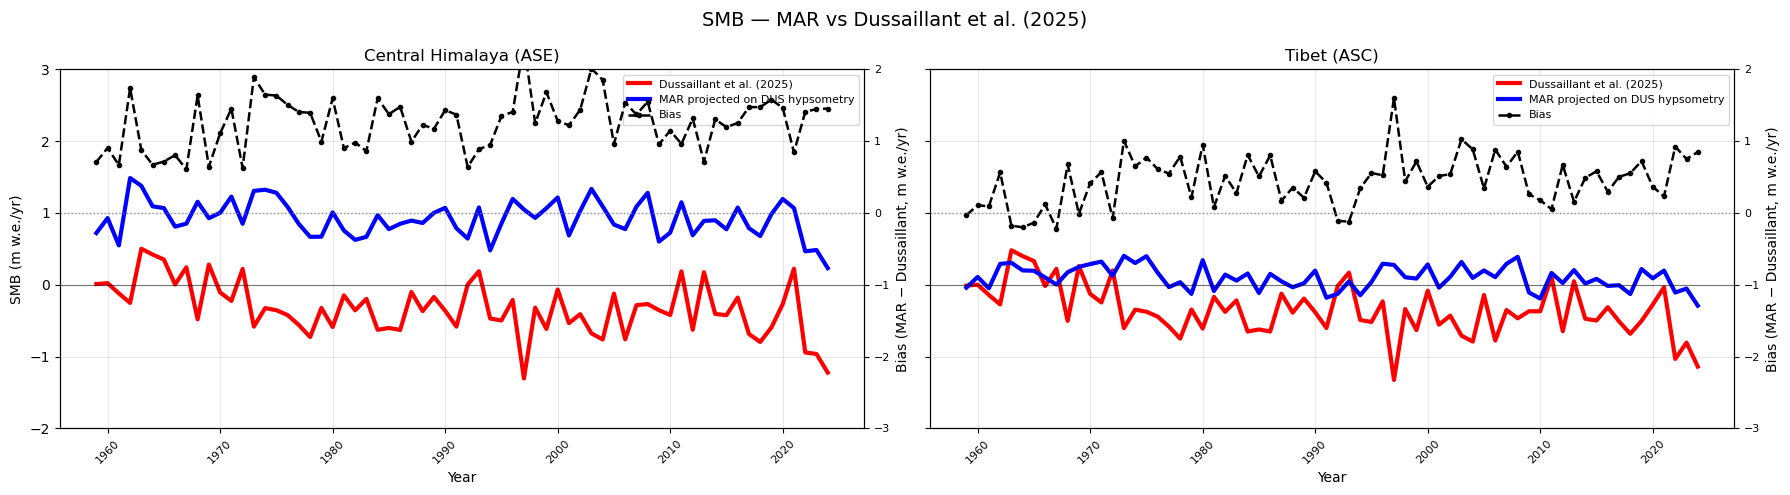

In [67]:
# Projecting MAR SMB on Dussaillant Hypsométries : 1960 - 2024

yr_start_dus_long = '1959-01-16T12:00:00.000000000'
yr_stop_dus_long  = '2024-12-16T12:00:00.000000000'


smb_mar_ASE_dus_long = smb_MAR_rgi_projection(
    ds_SMB_ASE,
    SH,
    hypsometry_dus_ASE,
    yr_start_dus_long ,
    yr_stop_dus_long,
    dz
)

smb_mar_ASC_dus_long = smb_MAR_rgi_projection(
    ds_SMB_ASC,
    SH,
    hypsometry_dus_ASC,
    yr_start_dus_long ,
    yr_stop_dus_long,
    dz
)


df_remotes_sensing = [dus_ASE_df, dus_ASC_df]
df_mar = [smb_mar_ASE_dus_long, smb_mar_ASC_dus_long]
titles = ['Central Himalaya (ASE)', 'Tibet (ASC)']


yr_start = pd.to_datetime('1959-01-16T12:00:00.000000000').year
yr_stop = pd.to_datetime(yr_stop_dus).year

yrs_str = [str(y) for y in range(yr_start, yr_stop + 1)]

# Limites de l'axe SMB
y1_min = -2
y1_max = 3


# Limites de l'axe du bais
y2_min = -3
y2_max = 2


fig, axes = plt.subplots(
    1, 2,
    figsize=(18, 5),
    sharex=True,
    sharey=True
)

for ax, title, df, smb_mar in zip(
    axes, titles, df_remotes_sensing, df_mar
):

    # ========================================================
    # 1. Dussaillant
    # ========================================================
    cum_smb = df[yrs_str]

    weighted_mean_cum = (
        cum_smb.mul(df["area"], axis=0).sum(axis=0)
        / df["area"].sum()
    )

    years_dus = weighted_mean_cum.index.astype(int).to_numpy()
    values_dus = weighted_mean_cum.to_numpy()

    ax.plot(
        years_dus,
        values_dus,
        lw=3,
        label="Dussaillant et al. (2025)",
        color="red"
    )

    # ========================================================
    # 2. MAR
    # ========================================================
    smb_mar_sel = smb_mar.sel(
        time=smb_mar.time.dt.year.isin(
            range(yr_start, yr_stop + 1)
        )
    )

    years_mar = smb_mar_sel.time.dt.year.values
    values_mar = np.asarray(smb_mar_sel.values).squeeze()

    ax.plot(
        years_mar,
        values_mar,
        lw=3,
        label="MAR projected on DUS hypsometry",
        color="blue"
    )
    ax.set_ylim(y1_min, y1_max)
    
    # ========================================================
    # 3. BIAIS MAR - DUSSAILLANT
    # ========================================================
    dus_series = pd.Series(
        values_dus,
        index=years_dus
    )

    mar_series = pd.Series(
        values_mar,
        index=years_mar
    )

    comparison = pd.concat(
        [
            mar_series.rename("MAR"),
            dus_series.rename("DUS")
        ],
        axis=1,
        join="inner"
    ).sort_index()

    difference = comparison["MAR"] - comparison["DUS"]

    ax2 = ax.twinx()

    ax2.plot(
        difference.index,
        difference.values,
        color="black",
        lw=1.8,
        linestyle="--",
        marker="o",
        markersize=3,
        label="Bias"
    )

    ax2.axhline(
        0,
        color="gray",
        lw=1,
        linestyle=":",
        alpha=0.8
    )

    ax2.set_ylim(y2_min, y2_max)
    ax2.set_ylabel(
        "Bias (MAR − Dussaillant, m w.e./yr)",
        color="black"
    )

    ax2.tick_params(
        axis="y",
        labelsize=8,
        colors="black"
    )

    ax.set_title(title)
    ax.set_xlabel("Year")
    ax.grid(alpha=0.3)

    ax.axhline(
        0,
        color="black",
        lw=0.8,
        alpha=0.5
    )

    ax.tick_params(
        axis="x",
        labelsize=8,
        labelrotation=45
    )

    # Légende 
    handles1, labels1 = ax.get_legend_handles_labels()
    handles2, labels2 = ax2.get_legend_handles_labels()

    ax.legend(
        handles1 + handles2,
        labels1 + labels2,
        loc="best",
        fontsize=8
    )

axes[0].set_ylabel("SMB (m w.e./yr)")

plt.suptitle(
    "SMB — MAR vs Dussaillant et al. (2025)",
    fontsize=14
)

fig.savefig(
    "plots/MAR-DUS_bias_1960_HIM.png",
    dpi=300,
    bbox_inches="tight"
)

plt.tight_layout()
plt.show()

In [68]:
# Bias Statsistique - Maybe I should use 2000-2020 as a reference time period for Dussaillant

yr_start_dus_short = '2000-01-16T12:00:00.000000000'
yr_stop_dus_short  = '2025-12-16T12:00:00.000000000'

print("Year start:", yr_start_dus_short)
print("Year stop:", yr_stop_dus_short)

smb_mar_ASE_dus_short = smb_MAR_rgi_projection(
    ds_SMB_ASE,
    SH,
    hypsometry_dus_ASE,
    yr_start_dus_short,
    yr_stop_dus_short,
    dz
)

smb_mar_ASC_dus_short = smb_MAR_rgi_projection(
    ds_SMB_ASC,
    SH,
    hypsometry_dus_ASC,
    yr_start_dus_short,
    yr_stop_dus_short,
    dz
)



df_remotes_sensing = [dus_ASE_df, dus_ASC_df]
df_mar = [smb_mar_ASE_dus_short, smb_mar_ASC_dus_short]
titles = ['Central Himalaya (ASE)', 'Tibet (ASC)']


yr_start = pd.to_datetime(yr_start_dus).year
yr_stop = pd.to_datetime(yr_stop_dus).year

yrs_str = [str(y) for y in range(yr_start, yr_stop + 1)]

for title, df, smb_mar in zip(titles, df_remotes_sensing, df_mar):

    # Dussaillant : moyenne pondérée par surface
    cum_smb = df[yrs_str]

    weighted_mean_cum = (
        cum_smb.mul(df["area"], axis=0).sum(axis=0)
        / df["area"].sum()
    )

    years_dus = weighted_mean_cum.index.astype(int)

    dus_series = pd.Series(
        weighted_mean_cum.values,
        index=years_dus
    )

    # MAR : sélection des années
    smb_mar_sel = smb_mar.sel(
        time=smb_mar.time.dt.year.isin(
            range(yr_start, yr_stop + 1)
        )
    )

    mar_series = pd.Series(
        np.asarray(smb_mar_sel.values).squeeze(),
        index=smb_mar_sel.time.dt.year.values
    )

    # Comparaison sur les années communes
    comparison = pd.concat(
        [
            mar_series.rename("MAR"),
            dus_series.rename("DUS")
        ],
        axis=1,
        join="inner"
    ).sort_index()

    # Biais annuel : MAR - DUS
    bias = comparison["MAR"] - comparison["DUS"]

    # Statistiques
    print(f"\n{title}")
    print(f"Biais moyen   : {bias.mean():.3f} m w.e. yr⁻¹")
#    print(f"Biais médian  : {bias.median():.3f} m w.e. yr⁻¹")
    print(f"Écart-type    : {bias.std(ddof=1):.3f} m w.e. yr⁻¹")

Year start: 2000-01-16T12:00:00.000000000
Year stop: 2025-12-16T12:00:00.000000000


/home/fainx/micromamba/envs/Xav_2509/lib/python3.9/site-packages/xarray/groupers.py:326: FutureWarning: 'A-SEP' is deprecated and will be removed in a future version, please use 'YE-SEP' instead.
  self.index_grouper = pd.Grouper(
/home/fainx/micromamba/envs/Xav_2509/lib/python3.9/site-packages/dask/array/core.py:4849: PerformanceWarning: Increasing number of chunks by factor of 24
  result = blockwise(
/home/fainx/micromamba/envs/Xav_2509/lib/python3.9/site-packages/xarray/groupers.py:326: FutureWarning: 'A-SEP' is deprecated and will be removed in a future version, please use 'YE-SEP' instead.
  self.index_grouper = pd.Grouper(



Central Himalaya (ASE)
Biais moyen   : 1.324 m w.e. yr⁻¹
Écart-type    : 0.297 m w.e. yr⁻¹

Tibet (ASC)
Biais moyen   : 0.544 m w.e. yr⁻¹
Écart-type    : 0.274 m w.e. yr⁻¹


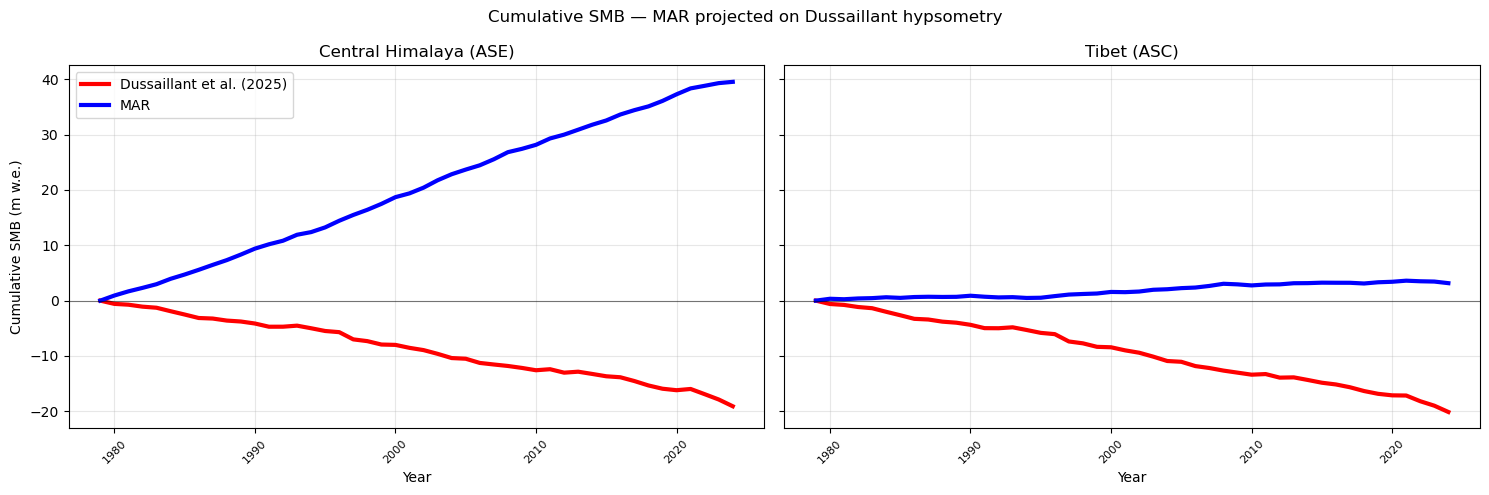

In [69]:
df_remotes_sensing = [dus_ASE_df, dus_ASC_df]
df_mar = [smb_mar_ASE_dus, smb_mar_ASC_dus]
titles = ['Central Himalaya (ASE)', 'Tibet (ASC)']

yr_start = pd.to_datetime(yr_start_dus).year
yr_stop = pd.to_datetime(yr_stop_dus).year

# Années pour sélectionner les colonnes de df_dus
yrs_str = [str(y) for y in range(yr_start, yr_stop + 1)]
# Années pour le graphique
yrs = np.arange(yr_start, yr_stop + 1)


fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5),
    sharex=True,
    sharey=True
)


for ax, title, df, smb_mar in zip(
    axes, titles, df_remotes_sensing, df_mar
):

    # ========================================================
    # Remote Sensing dataset
    # ========================================================
    cum_smb = df[yrs_str].cumsum(axis=1)
    weighted_mean_cum = (
        cum_smb.mul(df["area"], axis=0).sum(axis=0)
        / df["area"].sum()
    )
    # Ajouter un point initial à zéro
    yrs_plot = np.insert(yrs, 0, yr_start - 1)
    weighted_mean_cum_plot = np.insert(
        weighted_mean_cum.values,
        0,
        0
    )

    ax.plot(
        yrs_plot,
        weighted_mean_cum_plot,
        lw=3,
        label="Dussaillant et al. (2025)",
        color = 'red'
    )

    # ========================================================
    # MAR
    # ========================================================
    smb_mar_sel = smb_mar.sel(
        time=smb_mar.time.dt.year.isin(
            range(yr_start, yr_stop + 1)
        )
    )
    smb_mar_cum = smb_mar_sel.cumsum(dim="time")
    
    # Ajouter un point initial à zéro
    mar_years_plot = np.insert(
        smb_mar_cum.time.dt.year.values,
        0,
        yr_start - 1
    )
    smb_mar_cum_plot = np.insert(
        smb_mar_cum.values,
        0,
        0
    )

    ax.plot(
        mar_years_plot,
        smb_mar_cum_plot,
        lw=3,
        label="MAR",
        color = 'blue'
    )
    
    # ========================================================
    # MISE EN FORME du PLOT
    # ======================================================== 
    ax.set_title(title)
    ax.set_xlabel("Year")
    ax.grid(
        alpha=0.3
    )
    
    ax.axhline(
        0,
        color="black",
        lw=0.8,
        alpha=0.5
    )
    
    ax.tick_params(
        axis="x",
        labelsize=8,
        labelrotation=45
    )

axes[0].set_ylabel(
    "Cumulative SMB (m w.e.)"
)

axes[0].legend()

plt.suptitle(
    "Cumulative SMB — MAR projected on Dussaillant hypsometry"
)

fig.savefig(
    "plots/MAR-DUS_cumul_1980_HIM.png",
    dpi=300,
    bbox_inches="tight"
)

plt.tight_layout()
plt.show()

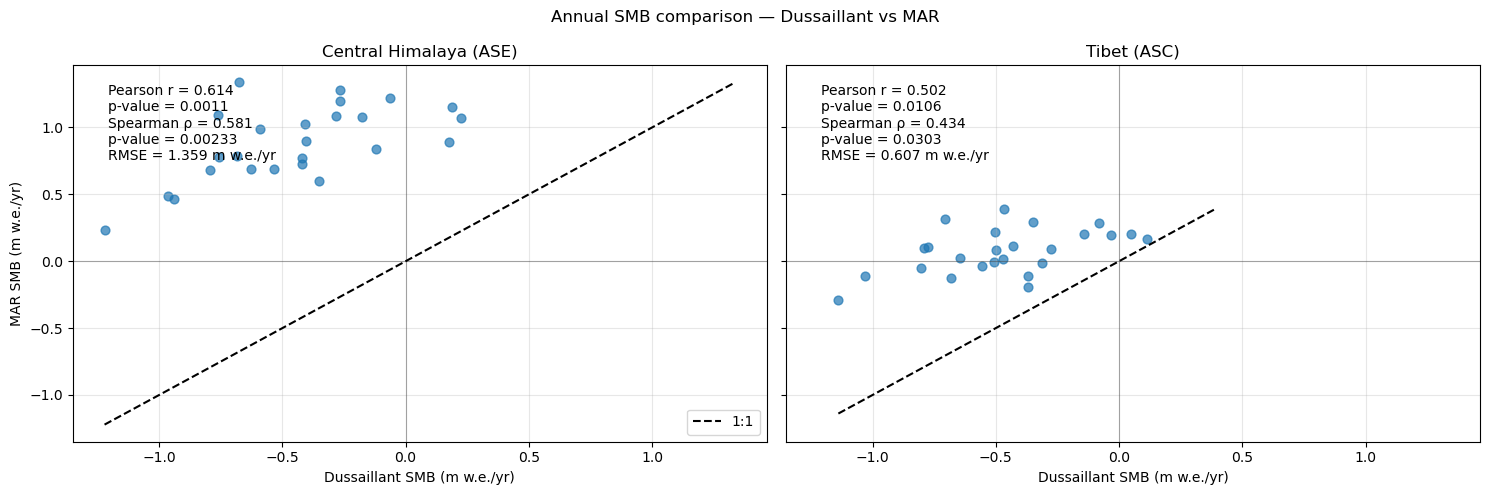

In [70]:
df_remotes_sensing = [dus_ASE_df, dus_ASC_df]
df_mar = [smb_mar_ASE_dus, smb_mar_ASC_dus]
titles = ['Central Himalaya (ASE)', 'Tibet (ASC)']
smb_mar_ASE_dus_short
yr_start = 2000
yr_stop = 2024

# Années
yrs_str = [str(y) for y in range(yr_start, yr_stop + 1)]


fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5),
    sharex=True,
    sharey=True
)


for ax, title, df, smb_mar in zip(
    axes, titles, df_remotes_sensing, df_mar
):

    # ========================================================
    # Dussaillant et al. (2025)
    # ========================================================

    smb_dus = (
        df[yrs_str]
        .mul(df["area"], axis=0)
        .sum(axis=0)
        / df["area"].sum()
    )

    # ========================================================
    # MAR
    # ========================================================

    smb_mar_sel = smb_mar.sel(
        time=smb_mar.time.dt.year.isin(
            range(yr_start, yr_stop + 1)
        )
    )

    # ========================================================
    # Alignement sur les années communes
    # ========================================================

    dus_series = pd.Series(
        smb_dus.values,
        index=smb_dus.index.astype(int)
    )

    mar_series = pd.Series(
        np.asarray(smb_mar_sel.values).squeeze(),
        index=smb_mar_sel.time.dt.year.values
    )

    comparison = pd.concat(
        [
            dus_series.rename("Dussaillant"),
            mar_series.rename("MAR")
        ],
        axis=1,
        join="inner"
    ).dropna()

    x = comparison["Dussaillant"].values
    y = comparison["MAR"].values

    # ========================================================
    # Calcul des indicateurs et p-values
    # ========================================================

    pearson, p_pearson = pearsonr(x, y)
    spearman, p_spearman = spearmanr(x, y)
    rmse = np.sqrt(np.mean((y - x) ** 2))

    # ========================================================
    # Scatter plot
    # ========================================================

    ax.scatter(
        x,
        y,
        s=40,
        alpha=0.7,
    )

    # ========================================================
    # Ligne 1:1
    # ========================================================

    xmin = min(x.min(), y.min())
    xmax = max(x.max(), y.max())

    ax.plot(
        [xmin, xmax],
        [xmin, xmax],
        color="black",
        linestyle="--",
        lw=1.5,
        label="1:1"
    )

    # ========================================================
    # Affichage des indicateurs
    # ========================================================

    ax.text(
        0.05, 0.95,
        f"Pearson r = {pearson:.3f}\n"
        f"p-value = {p_pearson:.3g}\n"
        f"Spearman ρ = {spearman:.3f}\n"
        f"p-value = {p_spearman:.3g}\n"
        f"RMSE = {rmse:.3f} m w.e./yr",
        transform=ax.transAxes,
        verticalalignment="top"
    )

    # ========================================================
    # Mise en forme
    # ========================================================

    ax.set_title(title)
    ax.set_xlabel("Dussaillant SMB (m w.e./yr)")
    ax.grid(alpha=0.3)

    ax.axhline(
        0,
        color="black",
        lw=0.8,
        alpha=0.3
    )

    ax.axvline(
        0,
        color="black",
        lw=0.8,
        alpha=0.3
    )


axes[0].set_ylabel("MAR SMB (m w.e./yr)")

axes[0].legend()

plt.suptitle(
    "Annual SMB comparison — Dussaillant vs MAR"
)

fig.savefig(
    "plots/MAR-DUS_corel_1980_HIM.png",
    dpi=300,
    bbox_inches="tight"
)

plt.tight_layout()
plt.show()

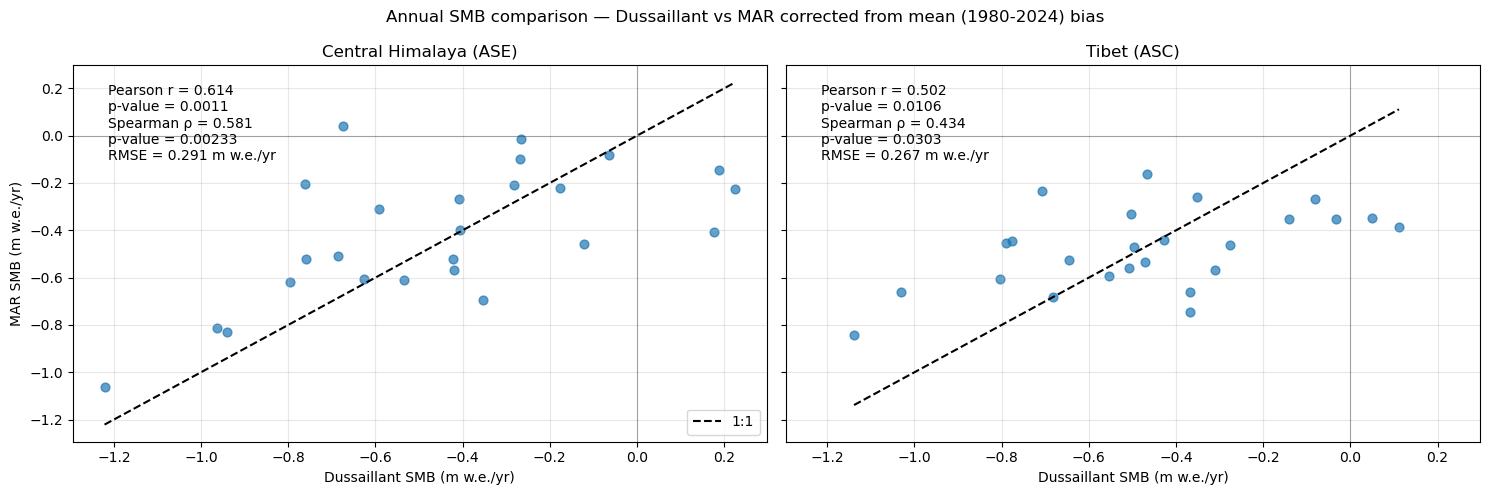

In [71]:
smb_mar_ASE_dus_cor = smb_mar_ASE_dus - 1.296
smb_mar_ASC_dus_cor = smb_mar_ASC_dus - 0.552 

df_remotes_sensing = [dus_ASE_df, dus_ASC_df]
df_mar = [smb_mar_ASE_dus_cor, smb_mar_ASC_dus_cor]
titles = ['Central Himalaya (ASE)', 'Tibet (ASC)']

yr_start = 2000
yr_stop = 2024

# Années
yrs_str = [str(y) for y in range(yr_start, yr_stop + 1)]


fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5),
    sharex=True,
    sharey=True
)


for ax, title, df, smb_mar in zip(
    axes, titles, df_remotes_sensing, df_mar
):

    # ========================================================
    # Dussaillant et al. (2025)
    # ========================================================

    smb_dus = (
        df[yrs_str]
        .mul(df["area"], axis=0)
        .sum(axis=0)
        / df["area"].sum()
    )

    # ========================================================
    # MAR
    # ========================================================

    smb_mar_sel = smb_mar.sel(
        time=smb_mar.time.dt.year.isin(
            range(yr_start, yr_stop + 1)
        )
    )

    # ========================================================
    # Alignement sur les années communes
    # ========================================================

    dus_series = pd.Series(
        smb_dus.values,
        index=smb_dus.index.astype(int)
    )

    mar_series = pd.Series(
        np.asarray(smb_mar_sel.values).squeeze(),
        index=smb_mar_sel.time.dt.year.values
    )

    comparison = pd.concat(
        [
            dus_series.rename("Dussaillant"),
            mar_series.rename("MAR")
        ],
        axis=1,
        join="inner"
    ).dropna()

    x = comparison["Dussaillant"].values
    y = comparison["MAR"].values

    # ========================================================
    # Calcul des indicateurs et p-values
    # ========================================================

    pearson, p_pearson = pearsonr(x, y)
    spearman, p_spearman = spearmanr(x, y)
    rmse = np.sqrt(np.mean((y - x) ** 2))

    # ========================================================
    # Scatter plot
    # ========================================================

    ax.scatter(
        x,
        y,
        s=40,
        alpha=0.7,
    )

    # ========================================================
    # Ligne 1:1
    # ========================================================

    xmin = min(x.min(), y.min())
    xmax = max(x.max(), y.max())

    ax.plot(
        [xmin, xmax],
        [xmin, xmax],
        color="black",
        linestyle="--",
        lw=1.5,
        label="1:1"
    )

    # ========================================================
    # Affichage des indicateurs
    # ========================================================

    ax.text(
        0.05, 0.95,
        f"Pearson r = {pearson:.3f}\n"
        f"p-value = {p_pearson:.3g}\n"
        f"Spearman ρ = {spearman:.3f}\n"
        f"p-value = {p_spearman:.3g}\n"
        f"RMSE = {rmse:.3f} m w.e./yr",
        transform=ax.transAxes,
        verticalalignment="top"
    )

    # ========================================================
    # Mise en forme
    # ========================================================

    ax.set_title(title)
    ax.set_xlabel("Dussaillant SMB (m w.e./yr)")
    ax.grid(alpha=0.3)

    ax.axhline(
        0,
        color="black",
        lw=0.8,
        alpha=0.3
    )

    ax.axvline(
        0,
        color="black",
        lw=0.8,
        alpha=0.3
    )


axes[0].set_ylabel("MAR SMB (m w.e./yr)")

axes[0].legend()

plt.suptitle(
    "Annual SMB comparison — Dussaillant vs MAR corrected from mean (1980-2024) bias"
)

fig.savefig(
    "plots/MARcor-DUS_corel_1980_HIM.png",
    dpi=300,
    bbox_inches="tight"
)

plt.tight_layout()
plt.show()

## Approach 2 : use HIMAP areas

#### On a combiné Eastern and Western HIM : ds_SMB_HIM
#### On garde Gangdise Mountains: ds_SMB_GM

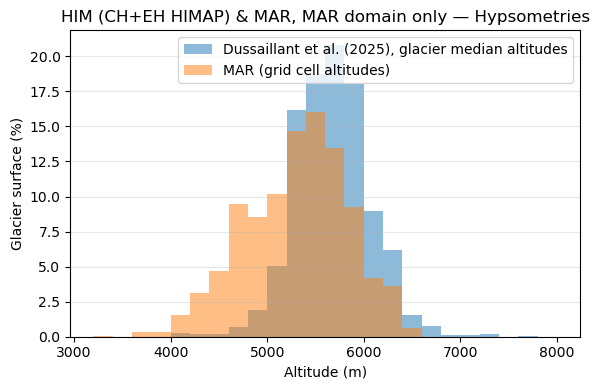

Surface glaciaire totale RGI : 6110.45 km²
Surface glaciaire totale MAR : 8166.44 km²
Somme RGI : 100.00 %
Somme MAR : 100.00 %


In [91]:
# HYPSOMETRIE COMPAREE Dussaillant et MAR - ASC

cell_area = 7 * 7      # km²

# ============================================================
# 1. RGI 6.0 — distribution selon Zmed
# ============================================================

df = dus_df_HIM.copy()

# Surface glaciaire totale RGI
total_area_rgi = df["area"].sum()

# ============================================================
# 2. MAR / ICE — distribution selon altitude
# ============================================================

# Altitudes ASC
altitudes = SH.where(
    ( (mask_smb ==  region_id["Central Himalaya"]) | (mask_smb ==  region_id["Eastern Himalaya"]) ) &
    (ICE > 0))


# Surface glaciaire par cellule
ice_area = ICE/100 * cell_area

# Garder uniquement Région + glace
ice_area = ice_area.where(
    ( (mask_smb ==  region_id["Central Himalaya"]) | (mask_smb ==  region_id["Eastern Himalaya"]) ) &
    (ICE > 0)
)

# Conversion en tableaux 1D
altitudes_flat = altitudes.values.flatten()
ice_area_flat = ice_area.values.flatten()

# Retirer les NaN
valid = (
    np.isfinite(altitudes_flat) &
    np.isfinite(ice_area_flat)
)

altitudes_flat = altitudes_flat[valid]
ice_area_flat = ice_area_flat[valid]

# ============================================================
# 3. Classes d'altitude communes aux deux méthodes
# ============================================================

zmin = np.floor(
    min(df["Zmed"].min(), altitudes_flat.min()) / dz
) * dz

zmax = np.ceil(
    max(df["Zmed"].max(), altitudes_flat.max()) / dz
) * dz

bins = np.arange(zmin, zmax + dz, dz)

z_center = (bins[:-1] + bins[1:]) / 2


# ============================================================
# 4. RGI — surface par classe de Zmed
# ============================================================

area_rgi_by_bin, _ = np.histogram(
    df["Zmed"],
    bins=bins,
    weights=df["area"]
)

percentage_rgi = (
    area_rgi_by_bin /
    total_area_rgi
) * 100


# ============================================================
# 5. MAR / ICE — surface par classe d'altitude
# ============================================================

area_mar_by_bin, _ = np.histogram(
    altitudes_flat,
    bins=bins,
    weights=ice_area_flat
)

total_ice_area = area_mar_by_bin.sum()

percentage_mar = (
    area_mar_by_bin /
    total_ice_area
) * 100


# ============================================================
# 6. PLOT COMPARATIF
# ============================================================

plt.figure(figsize=(6, 4))

# RGI 6.0
plt.bar(
    z_center,
    percentage_rgi,
    width=dz,
    align="center",
    alpha=0.5,
    label="Dussaillant et al. (2025), glacier median altitudes"
)

# MAR / ICE
plt.bar(
    z_center,
    percentage_mar,
    width=dz,
    align="center",
    alpha=0.5,
    label="MAR (grid cell altitudes)"
)

plt.xlabel("Altitude (m)")
plt.ylabel("Glacier surface (%)")
plt.title("HIM (CH+EH HIMAP) & MAR, MAR domain only — Hypsometries")

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()


# ============================================================
# 7. VÉRIFICATIONS
# ============================================================

print(
    f"Surface glaciaire totale RGI : "
    f"{total_area_rgi:.2f} km²"
)

print(
    f"Surface glaciaire totale MAR : "
    f"{total_ice_area:.2f} km²"
)

print(
    f"Somme RGI : "
    f"{percentage_rgi.sum():.2f} %"
)

print(
    f"Somme MAR : "
    f"{percentage_mar.sum():.2f} %"
)


hypsometry_dus_HIM = pd.DataFrame({
    "altitude_m": z_center,
    "percentage_rgi": percentage_rgi
})

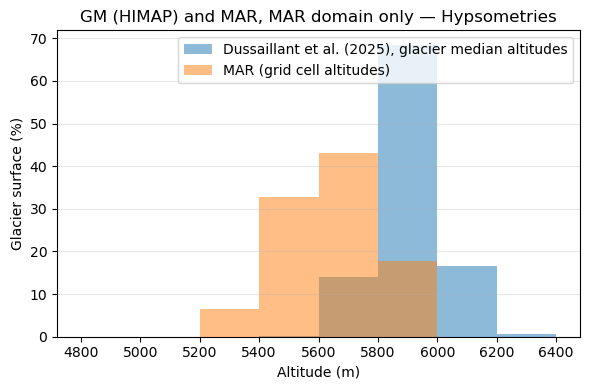

Surface glaciaire totale RGI : 427.04 km²
Surface glaciaire totale MAR : 328.67 km²
Somme RGI : 100.00 %
Somme MAR : 100.00 %


In [90]:
# HYPSOMETRIE COMPAREE Dussaillant et MAR - ASC

cell_area = 7 * 7      # km²

# ============================================================
# 1. RGI 6.0 — distribution selon Zmed
# ============================================================

df = dus_df_GM.copy()

# Surface glaciaire totale RGI
total_area_rgi = df["area"].sum()

# ============================================================
# 2. MAR / ICE — distribution selon altitude
# ============================================================

# Altitudes ASC
altitudes = SH.where(
    ( (mask_smb ==  region_id["Gangdise Mountains"]) ) &
    (ICE > 0))


# Surface glaciaire par cellule
ice_area = ICE/100 * cell_area

# Garder uniquement Région + glace
ice_area = ice_area.where(
    ( (mask_smb ==  region_id["Gangdise Mountains"]) ) &
    (ICE > 0))


# Conversion en tableaux 1D
altitudes_flat = altitudes.values.flatten()
ice_area_flat = ice_area.values.flatten()

# Retirer les NaN
valid = (
    np.isfinite(altitudes_flat) &
    np.isfinite(ice_area_flat)
)

altitudes_flat = altitudes_flat[valid]
ice_area_flat = ice_area_flat[valid]

# ============================================================
# 3. Classes d'altitude communes aux deux méthodes
# ============================================================

zmin = np.floor(
    min(df["Zmed"].min(), altitudes_flat.min()) / dz
) * dz

zmax = np.ceil(
    max(df["Zmed"].max(), altitudes_flat.max()) / dz
) * dz

bins = np.arange(zmin, zmax + dz, dz)

z_center = (bins[:-1] + bins[1:]) / 2


# ============================================================
# 4. RGI — surface par classe de Zmed
# ============================================================

area_rgi_by_bin, _ = np.histogram(
    df["Zmed"],
    bins=bins,
    weights=df["area"]
)

percentage_rgi = (
    area_rgi_by_bin /
    total_area_rgi
) * 100


# ============================================================
# 5. MAR / ICE — surface par classe d'altitude
# ============================================================

area_mar_by_bin, _ = np.histogram(
    altitudes_flat,
    bins=bins,
    weights=ice_area_flat
)

total_ice_area = area_mar_by_bin.sum()

percentage_mar = (
    area_mar_by_bin /
    total_ice_area
) * 100


# ============================================================
# 6. PLOT COMPARATIF
# ============================================================

plt.figure(figsize=(6, 4))

# RGI 6.0
plt.bar(
    z_center,
    percentage_rgi,
    width=dz,
    align="center",
    alpha=0.5,
    label="Dussaillant et al. (2025), glacier median altitudes"
)

# MAR / ICE
plt.bar(
    z_center,
    percentage_mar,
    width=dz,
    align="center",
    alpha=0.5,
    label="MAR (grid cell altitudes)"
)

plt.xlabel("Altitude (m)")
plt.ylabel("Glacier surface (%)")
plt.title("GM (HIMAP) and MAR, MAR domain only — Hypsometries")

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()


# ============================================================
# 7. VÉRIFICATIONS
# ============================================================

print(
    f"Surface glaciaire totale RGI : "
    f"{total_area_rgi:.2f} km²"
)

print(
    f"Surface glaciaire totale MAR : "
    f"{total_ice_area:.2f} km²"
)

print(
    f"Somme RGI : "
    f"{percentage_rgi.sum():.2f} %"
)

print(
    f"Somme MAR : "
    f"{percentage_mar.sum():.2f} %"
)


hypsometry_dus_GM = pd.DataFrame({
    "altitude_m": z_center,
    "percentage_rgi": percentage_rgi
})

In [98]:
# Projecting MAR SMB on Dussaillant Hypsométries

yr_start_dus = '1980-01-16T12:00:00.000000000'
yr_stop_dus  = '2024-12-16T12:00:00.000000000'

smb_mar_HIM_dus = smb_MAR_rgi_projection(
    ds_SMB_HIM,
    SH,
    hypsometry_dus_HIM,
    yr_start_dus,
    yr_stop_dus,
    dz
)

smb_mar_GM_dus = smb_MAR_rgi_projection(
    ds_SMB_GM,
    SH,
    hypsometry_dus_GM,
    yr_start_dus,
    yr_stop_dus,
    dz
)

/home/fainx/micromamba/envs/Xav_2509/lib/python3.9/site-packages/xarray/groupers.py:326: FutureWarning: 'A-SEP' is deprecated and will be removed in a future version, please use 'YE-SEP' instead.
  self.index_grouper = pd.Grouper(
/home/fainx/micromamba/envs/Xav_2509/lib/python3.9/site-packages/dask/array/core.py:4849: PerformanceWarning: Increasing number of chunks by factor of 24
  result = blockwise(
/home/fainx/micromamba/envs/Xav_2509/lib/python3.9/site-packages/xarray/groupers.py:326: FutureWarning: 'A-SEP' is deprecated and will be removed in a future version, please use 'YE-SEP' instead.
  self.index_grouper = pd.Grouper(


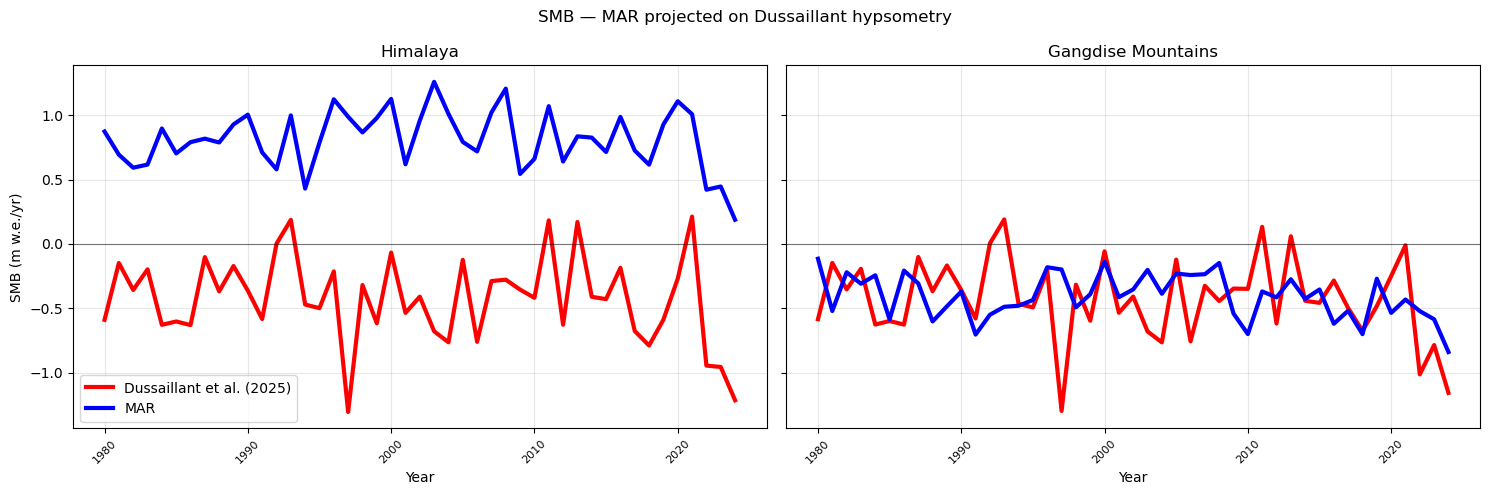

In [99]:
df_remotes_sensing = [dus_df_HIM, dus_df_GM]
df_mar = [smb_mar_HIM_dus, smb_mar_GM_dus]
titles = ['Himalaya', 'Gangdise Mountains']


yr_start = pd.to_datetime(yr_start_dus).year
yr_stop = pd.to_datetime(yr_stop_dus).year

# Années pour sélectionner les colonnes de df_dus
yrs_str = [str(y) for y in range(yr_start, yr_stop + 1)]
# Années pour le graphique
yrs = np.arange(yr_start, yr_stop + 1)


fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5),
    sharex=True,
    sharey=True
)


for ax, title, df, smb_mar in zip(
    axes, titles, df_remotes_sensing, df_mar
):

    # ========================================================
    # Remote Sensing dataset
    # ========================================================
    cum_smb = df[yrs_str]#.cumsum(axis=1)
    weighted_mean_cum = (
        cum_smb.mul(df["area"], axis=0).sum(axis=0)
        / df["area"].sum()
    )

    ax.plot(
        yrs,
        weighted_mean_cum,
        lw=3,
        label="Dussaillant et al. (2025)",
        color = 'red'
    )

    # ========================================================
    # MAR
    # ========================================================
    smb_mar_sel = smb_mar.sel(
        time=smb_mar.time.dt.year.isin(
            range(yr_start, yr_stop + 1)
        )
    )
    smb_mar_cum = smb_mar_sel#.cumsum(dim="time")
    
    ax.plot(
        smb_mar_cum.time.dt.year.values,
        smb_mar_cum,
        lw=3,
        label="MAR",
        color = 'blue'
    )
    
    # ========================================================
    # MISE EN FORME du PLOT
    # ======================================================== 
    ax.set_title(title)
    ax.set_xlabel("Year")
    ax.grid(
        alpha=0.3
    )
    
    ax.axhline(
        0,
        color="black",
        lw=0.8,
        alpha=0.5
    )
    
    ax.tick_params(
        axis="x",
        labelsize=8,
        labelrotation=45
    )

axes[0].set_ylabel(
    "SMB (m w.e./yr)"
)

axes[0].legend()

plt.suptitle(
    "SMB — MAR projected on Dussaillant hypsometry"
)

fig.savefig(
    "plots/MAR-DUS_1980_HIM.png",
    dpi=300,
    bbox_inches="tight"
)


plt.tight_layout()
plt.show()

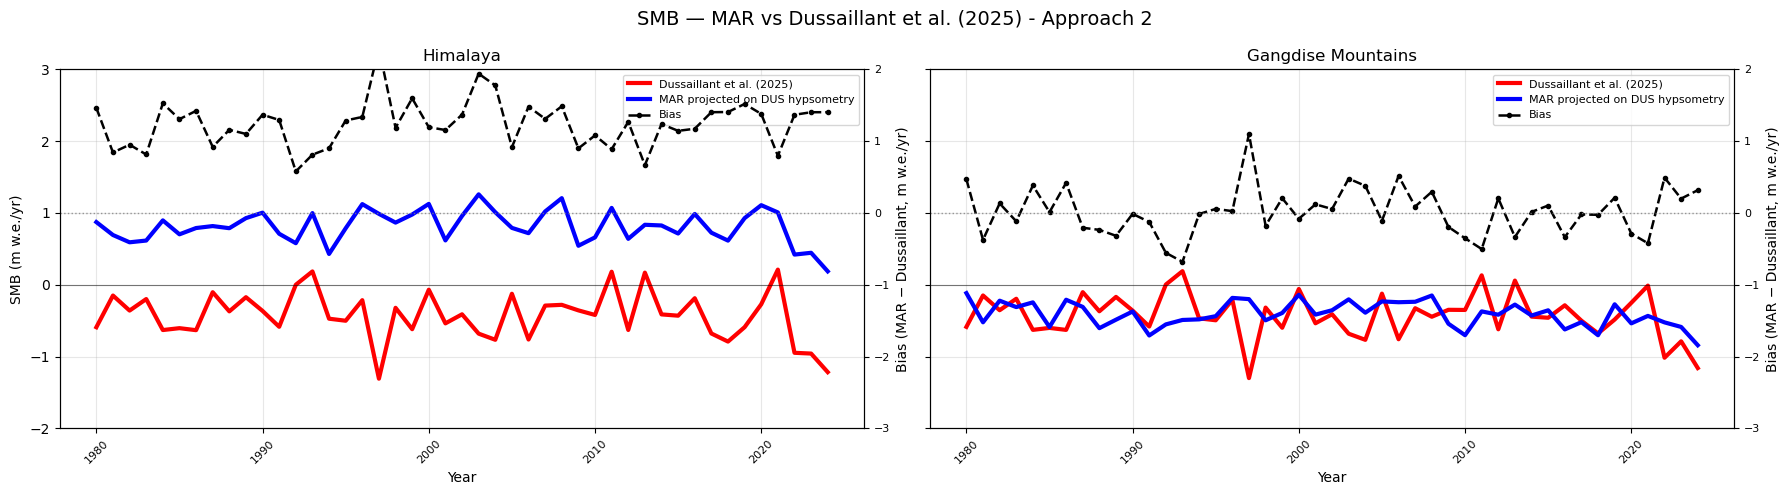

In [102]:
df_remotes_sensing = [dus_df_HIM, dus_df_GM]
df_mar = [smb_mar_HIM_dus, smb_mar_GM_dus]
titles = ['Himalaya', 'Gangdise Mountains']

yr_start = pd.to_datetime(yr_start_dus).year
yr_stop = pd.to_datetime(yr_stop_dus).year

yrs_str = [str(y) for y in range(yr_start, yr_stop + 1)]

# Limites de l'axe SMB
y1_min = -2
y1_max = 3


# Limites de l'axe du bais
y2_min = -3
y2_max = 2


fig, axes = plt.subplots(
    1, 2,
    figsize=(18, 5),
    sharex=True,
    sharey=True
)

for ax, title, df, smb_mar in zip(
    axes, titles, df_remotes_sensing, df_mar
):

    # ========================================================
    # 1. Dussaillant
    # ========================================================
    cum_smb = df[yrs_str]

    weighted_mean_cum = (
        cum_smb.mul(df["area"], axis=0).sum(axis=0)
        / df["area"].sum()
    )

    years_dus = weighted_mean_cum.index.astype(int).to_numpy()
    values_dus = weighted_mean_cum.to_numpy()

    ax.plot(
        years_dus,
        values_dus,
        lw=3,
        label="Dussaillant et al. (2025)",
        color="red"
    )

    # ========================================================
    # 2. MAR
    # ========================================================
    smb_mar_sel = smb_mar.sel(
        time=smb_mar.time.dt.year.isin(
            range(yr_start, yr_stop + 1)
        )
    )

    years_mar = smb_mar_sel.time.dt.year.values
    values_mar = np.asarray(smb_mar_sel.values).squeeze()

    ax.plot(
        years_mar,
        values_mar,
        lw=3,
        label="MAR projected on DUS hypsometry",
        color="blue"
    )
    ax.set_ylim(y1_min, y1_max)
    
    # ========================================================
    # 3. BIAIS MAR - DUSSAILLANT
    # ========================================================
    dus_series = pd.Series(
        values_dus,
        index=years_dus
    )

    mar_series = pd.Series(
        values_mar,
        index=years_mar
    )

    comparison = pd.concat(
        [
            mar_series.rename("MAR"),
            dus_series.rename("DUS")
        ],
        axis=1,
        join="inner"
    ).sort_index()

    difference = comparison["MAR"] - comparison["DUS"]

    ax2 = ax.twinx()

    ax2.plot(
        difference.index,
        difference.values,
        color="black",
        lw=1.8,
        linestyle="--",
        marker="o",
        markersize=3,
        label="Bias"
    )

    ax2.axhline(
        0,
        color="gray",
        lw=1,
        linestyle=":",
        alpha=0.8
    )

    ax2.set_ylim(y2_min, y2_max)
    ax2.set_ylabel(
        "Bias (MAR − Dussaillant, m w.e./yr)",
        color="black"
    )

    ax2.tick_params(
        axis="y",
        labelsize=8,
        colors="black"
    )

    ax.set_title(title)
    ax.set_xlabel("Year")
    ax.grid(alpha=0.3)

    ax.axhline(
        0,
        color="black",
        lw=0.8,
        alpha=0.5
    )

    ax.tick_params(
        axis="x",
        labelsize=8,
        labelrotation=45
    )

    # Légende 
    handles1, labels1 = ax.get_legend_handles_labels()
    handles2, labels2 = ax2.get_legend_handles_labels()

    ax.legend(
        handles1 + handles2,
        labels1 + labels2,
        loc="best",
        fontsize=8
    )

axes[0].set_ylabel("SMB (m w.e./yr)")

plt.suptitle(
    "SMB — MAR vs Dussaillant et al. (2025) - Approach 2",
    fontsize=14
)

fig.savefig(
    "plots/MAR-DUS_bias_1980_HIM_Approach_2.png",
    dpi=300,
    bbox_inches="tight"
)


plt.tight_layout()
plt.show()